# EE / CprE / CybE 3250: Machine Learning for Electrical, Computer, and Cybersecurity Engineering
## Lab-06: Attention, Transformers, and Natural Language Processing
> *[Note from your instructor: natural (human) language presents significantly different challenges when compared to the data we've looked at previously: words are organized into sequences, meaning is often context dependent, and important information may be separated by many intervening words or sentences. In this lab, we will start by implementing and training early neural network approaches, including recurrent networks and encoder-decoder architectures, which are capable of working with language data, but struggle to capture long-range relationships. We will then proceed to an exploration of the key ideas behind attention and transformers, with an emphasis on developing intuition for how these systems represent, process, and generate language. As before, collaboration is encouraged, as is the use of generative AI for debugging and coding support. However, all conceptual answers must be your own work. You will be evaluated based on lab preparation (PreLab), responses to programming and conceptual questions (Lab), and demonstration of understanding (PostLab).]*

**Names:** 

**Group Name:**



### 0. Prelab
Please read through this entire document and answer the questions at the end under the “Prelab Questions” section header. These are due and will be checked at the beginning of the lab – please post if you have any questions.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
import torch
from d2l import torch as d2l
import torch.nn as nn
import torch.nn.functional as F

### 1. Converting Raw Text into Sequence Data

Thus far, we have primarily worked with numerical data represented as vectors, matrices, and tensors. However, many of today's most influential machine learning systems operate on a very different type of data: **human language**. Natural Language Processing (NLP) seeks to build models capable of understanding, generating, summarizing, translating, and reasoning about text. The recent success of Large Language Models (LLMs) has demonstrated just how powerful these methods can be, powering systems such as ChatGPT, Copilot, Gemini, and Claude.

In this lab, we will explore the foundational ideas underlying modern language models. Beginning with simple character-level predictors and progressing through recurrent neural networks, encoder-decoder architectures, attention mechanisms, and transformers, we will see how machines can learn patterns in text and generate surprisingly coherent language. While today's frontier AI systems contain billions of parameters, the fundamental ideas can be demonstrated with relatively compact models and surprisingly little code.

Before we can train a language model, we must first convert raw text into a numerical representation that our machine learning pipeline can process. The general workflow is:

* Load the text into memory as ordinary strings
* Split the text into tokens (words, subwords, or individual characters)
* Build lookup dictionaries that map tokens to integers and integers back to tokens
* Convert the token sequence into numerical training examples suitable for our models

While these preprocessing steps may seem simple, they form the foundation of nearly every modern NLP system.

To gain familiarity with this process, we will begin using a text corpus derived from Wikipedia, one of the world's largest collaboratively curated knowledge bases. It provides a large and diverse collection of natural language that is well suited for training and evaluating language models. The full Wikipedia text corpus is now quite massive (even when compressed it is measured in tens of GB, see [link](https://en.wikipedia.org/wiki/Wikipedia:Size_of_Wikipedia)), so we will start with a much smaller sample:


In [2]:
with open('data/scraped_data.txt', 'r', encoding='utf-8') as file:
    raw_text_body = file.read()

The `.txt` file is opened and read into a string after executing the code cell above. Next, lets look at the length and word count of the corpus. We can also take a look at some random text contained in this file. 

In [3]:
import random

print(f"Total character length of trimmed corpus: {len(raw_text_body):,}")
print(f"Approximate word count: {len(raw_text_body.split()):,}")

random_start = random.randint(300, len(raw_text_body) - 400)
random_snippet = raw_text_body[random_start:random_start + 400]
print('"...' + random_snippet.strip() + '..."')

Total character length of trimmed corpus: 758,921,286
Approximate word count: 120,627,404
"...[115] A shortage of gunpowder led Congress to authorize a naval expedition against The Bahamas to secure ordnance stored there. [116] On March 3, 1776, an American squadron under the command of Esek Hopkins landed at the east end of Nassau and encountered minimal resistance at Fort Montagu . Hopkins' troops then marched on Fort Nassau . Hopkins had promised governor Montfort Browne and the civili..."


Note that even this stripped down corpus is quite large when compared to our previous 3250 datasets. While having over 700M characters is reasonable for a language model to process, with the intent to keep lab compute times reasonable we will cut this down further. Feel free to experiment with this parameter to compare execution times for later sections of this lab as well as model performance. 

In [4]:
data_limit = 500000
raw_text_body = raw_text_body[:data_limit]

You may notice that the Wikipedia dataset contains quite a bit of additional text beyond the article content itself, including citations, formatting artifacts, markup, and other non-linguistic information. To make subsequent processing and analysis more straightforward, we provide the helper function `clean_text()`, which removes much of this extraneous content and produces a cleaner corpus for training our language models.

In [5]:
import re

def clean_text(raw_text):
    text = raw_text.lower()
    # Remove Wikipedia citations like [1], [12], etc.
    text = re.sub(r'\[\d+\]', '', text)
    # Keep only a-z, spaces, periods, and commas
    text = re.sub(r'[^a-z., ]', '', text)
    # Collapse multiple spaces into one
    text = re.sub(r'\s+', ' ', text)
    return text

cleaned_text = clean_text(raw_text_body)

Now we need to finish converting the raw text into pipeline-ready sequences of numerical indices. To do this, we must build two lookup dictionaries: `char_to_idx`, which maps characters to integer indices, and `idx_to_char`, which maps integer indices back to characters. 

For example, suppose our corpus contains only the characters: `unique_chars = ['a', 'c', 't']`. 
Then we might construct: `char_to_idx = {'a': 0, 'c': 1, 't': 2}` and `idx_to_char = {0: 'a', 1: 'c', 2: 't'}`. 
The word "cat" could then be represented numerically as: `[1, 0, 2]`

For each text dataset we encounter, we will use the helper function `build_vocab()` to identify the unique tokens present in the corpus and construct these dictionaries.

- **Q1.1)\:** Complete the implementation of `build_vocab()` below. The variable `unique_chars` is provided as a sorted list containing every unique character in the corpus. Use the `enumerate()` function to efficiently iterate through this list and construct both lookup dictionaries. Below, briefly describe your implementation. 

- **A1.1)\:** We first describe our dictionarys as empty, then we enumerate all the unique chars and construct the two mirrored dicts by appending via the update funtion.

In [7]:
def build_vocab(text):
    """Builds character-to-index and index-to-character mapping dictionaries."""
    unique_chars = sorted(list(set(text)))

# YOUR CODE STARTS HERE
    char_to_idx = dict()
    idx_to_char = dict()
    for i, c in enumerate(unique_chars):
        char_to_idx.update({c: i})
        idx_to_char.update({i: c})
        
# YOUR CODE ENDS HERE
    
    return char_to_idx, idx_to_char

# Call the function
char_to_idx, idx_to_char = build_vocab(cleaned_text)

# Print out the mappings to verify
print(char_to_idx)
print(idx_to_char)

for char in "cat":
    print(char_to_idx[char])

{' ': 0, ',': 1, '.': 2, 'a': 3, 'b': 4, 'c': 5, 'd': 6, 'e': 7, 'f': 8, 'g': 9, 'h': 10, 'i': 11, 'j': 12, 'k': 13, 'l': 14, 'm': 15, 'n': 16, 'o': 17, 'p': 18, 'q': 19, 'r': 20, 's': 21, 't': 22, 'u': 23, 'v': 24, 'w': 25, 'x': 26, 'y': 27, 'z': 28}
{0: ' ', 1: ',', 2: '.', 3: 'a', 4: 'b', 5: 'c', 6: 'd', 7: 'e', 8: 'f', 9: 'g', 10: 'h', 11: 'i', 12: 'j', 13: 'k', 14: 'l', 15: 'm', 16: 'n', 17: 'o', 18: 'p', 19: 'q', 20: 'r', 21: 's', 22: 't', 23: 'u', 24: 'v', 25: 'w', 26: 'x', 27: 'y', 28: 'z'}
5
3
22


Similar to what we just did with the `"cat"` example above, the helper functions `tokenize()` and `detokenize()` automate the process of converting between text and numerical representations. Using the lookup dictionaries created by `build_vocab()`, `tokenize()` converts a string into a sequence of integer indices, while `detokenize()` performs the reverse operation, converting a sequence of indices back into readable text. This encoding and decoding process serves as the bridge between human language and the numerical data required by machine learning models.

In [8]:
def tokenize(text, char_to_idx):
    """Encodes a string of text into an array of integer tokens."""
    return [char_to_idx[char] for char in text]


def detokenize(numerical_text, idx_to_char):
    """Decodes an array of integer tokens back into a text string."""
    return "".join([idx_to_char[idx] for idx in numerical_text])

print(tokenize("this lab", char_to_idx))
print(detokenize([11, 21, 0, 9, 20, 7, 3, 22], idx_to_char))

[22, 10, 11, 21, 0, 14, 3, 4]
is great


- **Q1.2:** One of the preprocessing steps performed by our text-cleaning function is converting all letters to lowercase. Suppose instead that we preserved capitalization, treating `"A"` and `"a"` as distinct tokens. How would this affect the vocabulary size and the token-to-index mappings generated by `build_vocab()`? Discuss both the potential advantages and disadvantages of retaining capitalization when training a language model.

- **A1.2:** It would double the number of distinct tokens (roughly) as every character would recieve a capital equivalent. The benefit is it allows the model to produce ALL CAPITAL TEXT TO SIMULATE YELLING as well as recognize if the user is yelling at them! In all seriousness it would just give the model more context to tone, ability to format sentences more clearly, at the cost of more parameters and compute and training needed.

- **Q1.3)\:** Our cleaning function `clean_text()` removes **all** numeric digits from the corpus. What effect would this have on a Wikipedia-trained model's ability to generate or reason about dates, quantities, or years? Would this be a bigger or smaller problem for a character-level model vs. a word-level model? 

- **A1.3)\:** It would be a bigger problem for character level as it might not be able to understand or get dates at all. Word level models at least are able to encode english versions of numeric digits (like, one, two ... twenty seven thousand).

Above we printed out the different characters included in the corpus. Let's plot a histogram to look at the distribution of these tokens. 

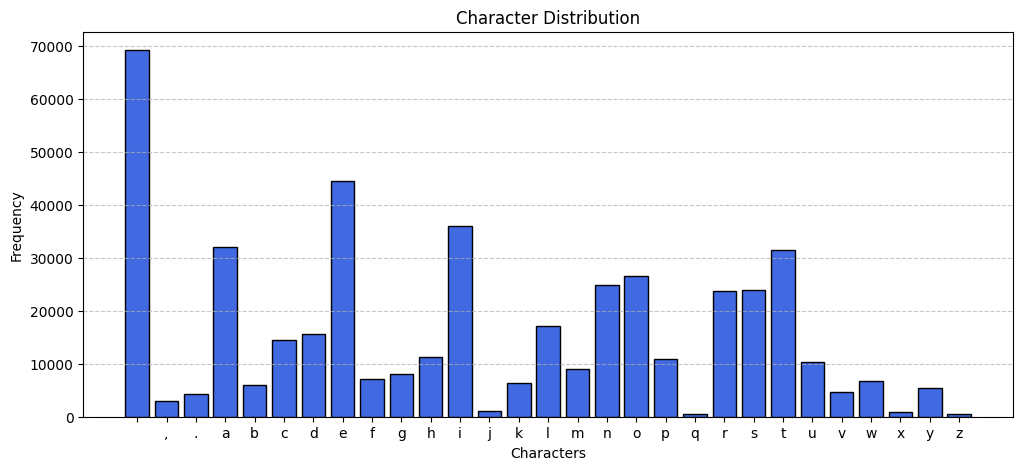

In [9]:
from collections import Counter

# Count character frequencies
char_counts = Counter(cleaned_text)

# Sort alphabetically or by frequency
sorted_chars = sorted(char_counts.items(), key=lambda x: x[0])
labels, values = zip(*sorted_chars)

# Plot the bar chart
plt.figure(figsize=(12, 5))
plt.bar(labels, values, color='royalblue', edgecolor='black')
plt.title('Character Distribution')
plt.xlabel('Characters')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Unsurprisingly, `' '` (space) is easily the most frequent token in the corpus. Intuition may tell you spaces could be ignored, but it should not be hard to think of why this would sabotage our model entirely.

Now we can define the function `create_windows()` to construct training examples from our text. To keep the problem manageable, we will work with relatively short chunks of 10-15 characters at a time.

When building sequence models, it is useful to think about how inputs and outputs relate to one another. In this lab, we will focus on a *sequence-to-sequence* (*seq2seq*) task. Given an input sequence of characters, the model will predict an output sequence of the same length, where each output corresponds to the next character that should appear in the text.

More specifically, we are using a *synchronous* seq2seq approach. The model generates one prediction for each input position, producing an output sequence whose length matches the input sequence. Because the model is only allowed to use information from previous characters when making a prediction, it is referred to as a causal model.

Later in this lab, we will encounter a more general form of seq2seq modeling known as an *encoder-decoder* architecture. In these *asynchronous* systems, the input and output sequences may have different lengths and even represent different languages or modalities. For example, an English sentence might be transformed into a French sentence, requiring the model to learn a structured mapping between two distinct sequences.

What this means for our current `create_windows()` function is that we need the dimensions of our `input_seq` to match the dimensions of our `target_seq` so that our model can make one prediction for each input character. 

- **Q1.4:** Complete the implementation of `create_windows()` below by filling in the `for` loop. For each position `i`, generate an `input_seq` of length `seq_len` and a corresponding `target_seq` of the same length, where each character in the target sequence represents the expected next prediction for the corresponding input character. In space for your response below, briefly explain your implementation and describe how the generated input and target sequences are related.

- **A1.4:** Basically, we take a window of i to i+seq_len for the input, and then we offset by +1 for the targets so that we have the next character to predict.

In [10]:
def create_windows(numerical_text, seq_len):
    inputs = []
    targets = []
    for i in range(len(numerical_text) - seq_len):

# YOUR CODE STARTS HERE
        inputs.append(numerical_text[i:i+seq_len])
        targets.append(numerical_text[i+1:i+seq_len+1])
# YOUR CODE ENDS HERE
        
    return np.array(inputs), np.array(targets)

- **Q1.5:** Our current implementation produces a *many-to-many* training dataset, where each character in the input sequence has a corresponding target character prediction. How would the data-generation process need to change if we instead wanted to train a *many-to-one* model, where the goal is to predict just a single output and not a sequence? Describe the modification that would be required to `create_windows()`, and explain what the resulting input and target sequences would represent. You may either provide the modified code or describe the changes in words.

- **A1.5:** If we wanted to traim a many to one, your input would still be the same, but the output would just be i + seq_len + 1 to predict the next character AFTER the entire input sequence.

Now we can construct our D2L-compatible dataset class. For the sake of abstraction and reusability, we will perform vocabulary construction, tokenization, and lookup-dictionary generation before creating the dataset object. As a result, the dataset's `__init__()` method will receive `numerical_text` (the output of our `tokenize()` function) directly as an input parameter. The dataset class can then focus on tasks specific to model training, including creating training and validation splits, constructing sequence windows using the `create_windows()` helper function, and storing the resulting `X` and `y` data as PyTorch tensors. Complete the implementation of `WikipediaDataset()` below. 

In [13]:
class WikipediaDataset(d2l.DataModule):
    def __init__(self, numerical_text, seq_len=12, batch_size=64):
        super().__init__()
        self.save_hyperparameters()
        
        # Split continuous numerical sequence to prevent train/val window overlap
        total_len = len(numerical_text)
        split_idx = int(total_len * 0.8)

        # Create X_train/Y_train and X_val/Y_val windows, and store them as tensors

# YOUR CODE STARTS HERE
        self.X_train, self.y_train = create_windows(numerical_text[:split_idx], seq_len)
        self.X_train = torch.tensor(self.X_train)
        self.y_train = torch.tensor(self.y_train)

        self.X_val, self.y_val = create_windows(numerical_text[split_idx+1:total_len], seq_len)
        self.X_val = torch.tensor(self.X_val)
        self.y_val = torch.tensor(self.y_val)
# YOUR CODE ENDS HERE

    def get_dataloader(self, train):
        if train:
            return self.get_tensorloader((self.X_train, self.y_train), train=True)
        else:
            return self.get_tensorloader((self.X_val, self.y_val), train=False)

Now, to test our full data pipeline, we first build our vocabulary outside of the class, and then pass `numerical_text` into the `__init__` block:

In [14]:
# Build dictionaries
char_to_idx, idx_to_char = build_vocab(cleaned_text)

# Tokenize Full Text
numerical_text = tokenize(cleaned_text, char_to_idx)
vocab_size = len(char_to_idx)

# Instantiate dataset by passing numerical_text
data = WikipediaDataset(numerical_text, seq_len=12, batch_size=64)
X, y = next(iter(data.get_dataloader(train=True)))

print("X shape (Features):", X.shape)
print("y shape (Targets):", y.shape) 

X shape (Features): torch.Size([64, 12])
y shape (Targets): torch.Size([64, 12])


### 2. RNNs as Next-Character Models

We are now ready to define a model capable of learning patterns in our Wikipedia corpus. As a first step, the model must learn the basic structure and syntax of the text before it can generate meaningful predictions. To accomplish this, we will use a compact LSTM-based language model, similar to the recurrent architectures explored in Lab-05.

The `__init__()` method below defines three primary components: an embedding layer, an LSTM layer, and an output layer. The parameters `vocab_size` and `embed_size` specify the number of unique tokens in our vocabulary and the dimensionality of the learned embeddings, respectively. During the forward pass, each token index in `X` is first transformed into a dense vector representation known as an *embedding*. These embeddings are then processed by the LSTM, which attempts to learn meaningful relationships within the character sequence. Finally, the output layer maps the LSTM's hidden representation back to the vocabulary space, producing a prediction for the next token at each position in the sequence.

While we will revisit embeddings in greater detail later in this lab, you can currently think of them as learned numerical representations that allow the model to capture relationships between tokens more effectively than simple one-hot encodings.

In [15]:
class RNNLanguageModel_v1(d2l.Classifier):
    def __init__(self, vocab_size, embed_size=64, num_hiddens=128, lr=0.05):
        super().__init__()
        self.save_hyperparameters()
        
        # Linear layer acts as embedding lookup
        self.input_projection = nn.Linear(vocab_size, embed_size, bias=False)
        
        # LSTM with input of size embed_size
        self.lstm = nn.LSTM(
            input_size=embed_size, 
            hidden_size=num_hiddens, 
            batch_first=True
        )
        
        # Output projection back to vocabulary space
        self.output = nn.Linear(num_hiddens, vocab_size)

As with previous models, we next need to define the `forward` block.

- **Q2.1:** Complete the implementation of the `forward()` method below. Begin by using `torch.nn.functional.one_hot()` to convert each token index in `X` into a one-hot encoded representation, expanding every integer token ID into a sparse vector containing a single 1 and zeros elsewhere. Once the data has been encoded, pass it through the embedding, LSTM, and output layers defined in the `__init__()` method to produce the model's predictions. In the space for your response below, briefly explain your implementation. If you encountered any difficulties while completing this section, describe the source of the confusion and how you resolved it. In particular, consider whether the challenge involved one-hot encoding, tensor shapes, embeddings, the LSTM layer, or understanding how the data flows through the network.

- **A2.1:** I was able to more or less copy the forward pass from lab 5. But then it turns out that I forgot to pass it through embedding!! After fixing that it was relatively straightforward.

In [20]:
@d2l.add_to_class(RNNLanguageModel_v1)
def forward(self, X):
        vocab_size = self.hparams['vocab_size']

# YOUR CODE STARTS HERE
        hot = torch.nn.functional.one_hot(X, vocab_size).float()
        embeds = self.input_projection(hot)
        output, (H, C) = self.lstm(embeds)
        logits = self.output(output)
# YOUR CODE ENDS HERE

        return logits

- **Q2.2:** Throughout previous labs, we have often used one-hot encodings for our target labels `y`, but this is the first time we have applied one-hot encoding to the input features `X`. Recall that when preparing the Wikipedia corpus, we mapped every character in the text to a unique integer ID. Why can't we simply feed these integer IDs directly into the LSTM? What incorrect assumptions might the model make if it interpreted the token IDs as ordinary numerical values? Explain how the one-hot encoding performed inside `forward()` addresses this problem and allows the model to treat each character as a distinct token rather than a quantity.

- **A2.2:** It could potentially not interpret it as actual token encodings and rather just try and predict numerical values. THe one hot encoding will prevent it from predicting non-token integers and keep it strictly predicting tokens and not some other numerical values.

There are a few additional `d2l.Classifier` methods that we must override to make the model compatible with our character-level language modeling task. The first of these is the `loss()` function. While PyTorch's `nn.CrossEntropyLoss` is designed to compare a 2nd-order tensor of predictions against a 1st-order tensor of target labels, our model produces a prediction for every position in every sequence. As a result, the output of the forward pass has shape `[Batch_Size, Seq_Len, Vocab_Size]`, while the target tensor has shape `[Batch_Size, Seq_Len]`.

Before computing the loss, we therefore reshape both tensors by temporarily collapsing the batch and sequence axes into a single axis. For example, if `y_hat` has shape `[64, 12, 29]`, it will be reshaped to `[768, 29]`, and the corresponding target tensor will be reshaped from `[64, 12]` to `[768]`. This allows `CrossEntropyLoss` to treat each character prediction as an independent classification task while leaving the overall structure of our model unchanged. Temporary tensors such as `flattened_y_hat` and `flattened_y` are used to perform this conversion locally within the loss function.

In [21]:
@d2l.add_to_class(RNNLanguageModel_v1)
def loss(self, y_hat, y):
        loss_fn = nn.CrossEntropyLoss(reduction='mean')
        
        # y_hat shape: [Batch, Seq_Len, Vocab_Size] -> [Batch * Seq_Len, Vocab_Size] (e.g., [768, 29])
        flattened_y_hat = y_hat.reshape(-1, y_hat.shape[-1])
        
        # y shape: [Batch, Seq_Len] -> [Batch * Seq_Len] (1D array of class index integers, e.g., [768])
        flattened_y = y.reshape(-1)
        
        return loss_fn(flattened_y_hat, flattened_y)


While we continue to train the model using `CrossEntropyLoss`, the raw loss values can be difficult to interpret in the context of language modeling. Cross entropy measures how well the model's predicted probability distribution matches the actual next token, but values such as $1.38$ or $3.36$ do not immediately tell us how uncertain the model is when making predictions.

For language models, it is therefore common to report **perplexity**, a metric derived directly from the cross-entropy loss:

$$\text{PPL} = e^{Loss}$$

Although perplexity is mathematically just the exponential of the loss, it has a useful interpretation: it approximates the number of tokens among which the model is effectively choosing. Lower perplexity indicates greater confidence and better predictive performance.

To understand this intuition, consider a vocabulary containing 29 unique characters:
- If the cross entropy is $3.37$, the perplexity is approximately $29.0$. This suggests that the model is performing little better than random guessing across the entire vocabulary.
- If the cross entropy is $1.39$, the perplexity is approximately $4.0$. In this case, the model has narrowed its uncertainty to roughly four plausible next-character choices rather than all twenty-nine.

While perplexity should not be interpreted too literally as an exact number of choices, it provides a much more intuitive measure of language-model performance than raw cross-entropy alone. As training progresses, decreasing perplexity indicates that the model is becoming less "confused" about what token should appear next.


- **Q2.3:** A language model achieves a cross-entropy loss of $0.00$ on a dataset. Compute the corresponding perplexity and explain what this reveals about the model's predictions. Is such a result likely to be observed in practice? Why or why not?

- **A2.3:** The perplexity would then be 1.0. It would be easy to say 0 but because its e^Loss e^0 is 1. This reveals how the model gets more and more confident and has better predictions it gets closer to 1.0. It is unlikely for this to actually occur, as the model will almost never give a particular token 100% confidence.

Perplexity does not directly influence the training process itself. The optimizer will continue to minimize the cross-entropy loss, and since the default implementation is sufficient for our needs, we do not need to override `configure_optimizers()` or modify the underlying `SGD` training procedure. Instead, we will use perplexity as an additional evaluation metric that provides a more intuitive view of the model's performance during training. To monitor both quantities, we update the `training_step()` and `validation_step()` methods below so that they compute and display perplexity on the ProgressBoard alongside the loss.

In [22]:
@d2l.add_to_class(RNNLanguageModel_v1)
def training_step(self, batch):
    X, y = batch
    y_hat = self(X)
    loss_val = self.loss(y_hat, y)
    
    # Calculate perplexity
    perplexity = torch.exp(loss_val)
    
    # Plot to the board
    self.plot('loss', loss_val, train=True)
    self.plot('perplexity', perplexity, train=True)
    
    self._printed_this_epoch = False
    
    return loss_val

@d2l.add_to_class(RNNLanguageModel_v1)
def validation_step(self, batch):
    X, y = batch
    y_hat = self(X)
    loss_val = self.loss(y_hat, y)
    
    perplexity_val = torch.exp(loss_val)
    
    self.plot('val_loss', loss_val, train=False)
    self.plot('val_perplexity', perplexity_val, train=False)
    
    return loss_val

Now for the fun part: generating text from the model's predictions. We will accomplish this using an *autoregressive* generation loop. In an autoregressive model, each new prediction becomes part of the input used to generate the next prediction. Starting from a user-provided text prompt, the model predicts the next character, appends it to the sequence, and then repeats the process. By repeatedly feeding its own outputs back into the model, we can generate text one character at a time.

- **Q2.4:** How does an autoregressive language model generate text from an initial prompt? Complete the `for` loop inside `predict_text()` to implement *greedy sampling* and then explain how the model's predictions are used to construct longer sequences of text. At each iteration, perform another forward pass through the model, extract the logits corresponding to the final time step, and select the token with the highest predicted probability using `argmax()`. This approach is known as *greedy* sampling because, at each step, we simply choose the most likely next token according to the model. Once selected, append the predicted token to the current sequence and continue generating text.

- **A2.4:** It generates text by prediciting one token (or character in this case) and then appends that to the input and feeds it back into itself.

In [39]:
def predict_text_v1(prefix, num_preds, model, char_to_idx, idx_to_char, seq_len=12):
    #model.eval()

    # If the prefix contains characters not in the vocabulary, we can use a special <unk> token or default to 0
    unk_id = char_to_idx.get('<unk>', char_to_idx.get('<UNK>', 0))
    outputs = [char_to_idx.get(ch, unk_id) for ch in prefix]
    
    with torch.no_grad():
        for _ in range(num_preds):

            # Grab the last seq_len characters to form the input sequence
            # Convert to tensors and feed into the model to get the next character prediction
            # Take the argmax of the logits to get the predicted character index
            # Add that index to the outputs list for the next iteration

# YOUR CODE STARTS HERE
            input_seq = torch.tensor(outputs[-seq_len:])
            pred_idx = (model(input_seq)[-1,:]).argmax().item()
# YOUR CODE ENDS HERE
                 
            outputs.append(pred_idx)
            
    return "".join([idx_to_char.get(i, '<unk>') for i in outputs])

We are now ready to instantiate our dataset, model, and trainer and begin training by calling `.fit()`. Initially, the model's goal is simply to learn the basic structure, syntax, and vocabulary patterns present in the corpus. As training progresses, we hope to observe both the loss and perplexity steadily decreasing, indicating that the model is becoming less uncertain about its predictions. The ultimate test, however, comes after training, when we use the `predict_text()` function to see whether the model can generate plausible continuations of previously unseen character sequences.

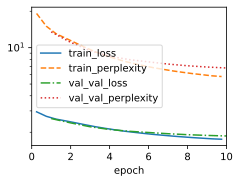

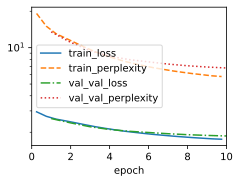

In [25]:
WikipediaData = WikipediaDataset(numerical_text, seq_len=12, batch_size=64)
model_1 = RNNLanguageModel_v1(vocab_size=vocab_size, num_hiddens=128, lr=0.05)

# Build the Trainer
model_trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1.0)

# Create custom board channels to set scale
model_trainer.plot_flag = True
model_trainer.board = d2l.ProgressBoard(
    xlabel='epoch', 
    xlim=[1, 20], 
    yscale='log' 
)

model_1.board = model_trainer.board
model_trainer.fit(model_1, WikipediaData)

Now that the model has been trained, let's see how well it performs on text that it has never encountered before. Experiment with the `predict_text()` function by providing your own prompts and observing how the generated text evolves. Try prompts of varying lengths and styles, and consider whether the model appears to have learned meaningful vocabulary, syntax, and language patterns from the training corpus.

In [40]:
prompt = "i hope this works well "
generated = predict_text_v1(
    prefix=prompt, 
    num_preds=20, 
    model=model_1, 
    char_to_idx=char_to_idx, 
    idx_to_char=idx_to_char)

print(f"Prompt: {prompt}")
print(f"Generated: {generated}")

Prompt: i hope this works well 
Generated: i hope this works well statice and and arti


- **Q2.5:** How well does your model perform on previously unseen character sequences? Based on the output of `predict_text()` for several different prompts, what limitations do you observe in the generated text? In particular, discuss how the greedy sampling strategy, which always chooses the most probable next token, might affect the diversity, creativity, and long-term coherence of the model's predictions, especially when using a relatively simple character-level RNN.

- **A2.5:** So, it does follow at least some structure, it generated "and" twice but didnt generate proper words otherwise. Its clearly biased towards common letters and phrases which you can see there are a lot of 'a' characters so its not good for creativity...

### 3. Word-Level Models

Now, let's switch from character-level tokens to word-level tokens and train the model to predict words instead of individual characters. One of the interesting aspects of language modeling is that this transition requires surprisingly few architectural changes. The overall structure of the model remains the same; most of the work involves changing how we tokenize the text and construct our vocabulary and lookup dictionaries.

The first step is to update how we process the Wikipedia corpus by defining the helper function `tokenize_words()`. To create meaningful word tokens, we will first convert all text to lowercase and then insert spaces around punctuation marks so that punctuation becomes its own token rather than remaining attached to neighboring words. For example: `"hello, world!"` becomes `["hello", ",", "world", "!"]`, allowing the tokenizer to treat words and punctuation as distinct units within the vocabulary.

In [41]:
def tokenize_words(text):
    text = text.lower()
    
    # Add spaces around punctuation marks so they detach from words
    punctuation = [".", ",", "!", "?", ";", ":", '"', "(", ")"]
    for p in punctuation:
        text = text.replace(p, f" {p} ")
        
    # Split on any whitespace
    tokens = text.split()
    return tokens

Now we can build our vocabulary, much as we previously did using the set of unique characters in the corpus. However, constructing a vocabulary from every unique word appearing in the Wikipedia dataset would result in a very large and unwieldy vocabulary containing tens of thousands of entries, including rare words, misspellings, abbreviations, and obscure names. Instead, we will limit the vocabulary to the most frequently occurring words, allowing the model to focus its capacity on the tokens it is most likely to encounter.

Of course, this raises an important question: what should happen when the model encounters a word that is not present in the vocabulary? To address this problem, we introduce a special token called `<UNK>` (short for unknown). Any word that does not appear in our selected vocabulary will be mapped to this token, allowing the model to continue processing text even when it encounters unfamiliar words. You may have seen `<UNK>` in the previous section, depending on what input you provided to `predict_text_v1()`.

- **Q3.1:** Complete the implementation of `build_word_vocab()` below. The variable counts contains the frequency of each word in the dataset. Use this information to create `top_words`, a list containing the `max_vocab_size - 1` most frequent words. Then prepend the special token `unk_token` to the beginning of this list (it is common practice to place special-purpose tokens at the start of a vocabulary) and use the resulting vocabulary to build both the `word_to_idx` and `idx_to_word` lookup dictionaries. In the response cell below, briefly explain your implementation. In particular, describe why we restrict the vocabulary size, the purpose of the `<UNK>` token, and how the lookup dictionaries enable conversion between words and numerical indices.

- **A3.1:** We cant allow a runaway vocabl list, as there are many tokens that would just show up one time and would otherwise be a wasted parameter. This is why we select k-1 top_words and add the unk token. The reason we add the unk token is because in a case where an input has a token that we excluded from out vocab. This unknown token is added to the vocab. Then we build the mirrored dictionaries (not sure if mirrored is the best term here) to encode/decode the tokens.

In [52]:
from collections import Counter

def build_word_vocab(tokens, max_vocab_size=10000, unk_token='<unk>'):
    # Frequency of each word
    counts = Counter(tokens)

    # Keep top (max_vocab_size - 1) most frequent words and include unk_token

# YOUR CODE STARTS HERE
    top_words = [word for word, count in counts.most_common(max_vocab_size - 1)]
    # Prepend unk_token to the beginning
    vocab = [unk_token] + top_words
    # build dicts
    word_to_idx = {word: idx for idx, word in enumerate(vocab)}
    idx_to_word = {idx: word for idx, word in enumerate(vocab)}

# YOUR CODE ENDS HERE

    return word_to_idx, idx_to_word


# Quick test of new function
tokens = tokenize_words(cleaned_text)
word_to_idx, idx_to_word = build_word_vocab(tokens, max_vocab_size=10)
print(word_to_idx)



{'<unk>': 0, '.': 1, ',': 2, 'the': 3, 'of': 4, 'to': 5, 'and': 6, 'wikipedia': 7, 'in': 8, 'a': 9}


Unlike our character-level tokenizer, a word-level vocabulary may now encounter words that do not appear in the dictionary, since we are only taking the `max_vocab_size` most common words. The helper function `numericalize_words()` addresses this by mapping all out-of-vocabulary words to the index associated with the special `<UNK>` token, allowing the model to continue processing unseen text.

In [48]:
def numericalize_words(tokens, word_to_idx, unk_token='<unk>'):
    unk_id = word_to_idx[unk_token]
    return [word_to_idx.get(word, unk_id) for word in tokens]

Let's visualize the most common words in our vocabulary using a bar chart. The helper function below computes the frequencies of the twenty most frequently occurring tokens and displays them as a labeled bar plot. 

In [49]:
def plot_top_word_frequencies(tokens, top_n=20, ignore_unk=True):
    # Count frequency of each word
    counts = Counter(tokens)
        
    # Extract top N most common words
    most_common = counts.most_common(top_n)
    words, frequencies = zip(*most_common)
    
    # Plotting
    plt.figure(figsize=(12, 5))
    bars = plt.bar(words, frequencies, color='skyblue', edgecolor='navy', alpha=0.8)
    
    # Add count values above each bar
    for bar in bars:
        height = bar.get_height()
        plt.annotate(
            f'{height:,}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),  # 3 points vertical offset
            textcoords="offset points",
            ha='center', va='bottom',
            fontsize=8
        )
        
    plt.title(f'Top {top_n} Most Frequent Words in Corpus', fontsize=14, fontweight='bold')
    plt.xlabel('Word Tokens', fontsize=12)
    plt.ylabel('Frequency Count', fontsize=12)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

We can then use these functions to generate the token vocabulary and visualize the most common tokens:

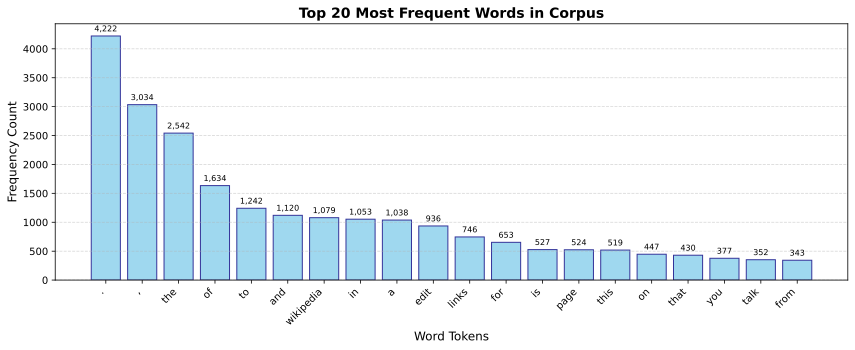

In [50]:
tokens = tokenize_words(cleaned_text)
word_to_idx, idx_to_word = build_word_vocab(tokens, max_vocab_size=10000)
numerical_tokens = numericalize_words(tokens, word_to_idx=word_to_idx)
plot_top_word_frequencies(tokens, top_n=20)

Recall that in the previous section, we one-hot encoded our character tokens and noted that a one-hot encoding followed by a linear layer effectively creates a learned *embedding*. While this approach is conceptually useful, it is not how embeddings are typically implemented in practice. Instead, PyTorch provides the optimized `nn.Embedding` layer, which performs the same underlying lookup operation more efficiently.

As a result, our new word-level model requires only a small modification to its architecture. We replace the manual one-hot encoding and initial projection step with an embedding layer that directly maps each token index to a learned dense vector representation. The remainder of the model remains largely unchanged: the LSTM processes the sequence of embeddings, and the output layer generates token predictions. We will continue to use the same cross-entropy loss function as before, though we must once again override the `loss()` method to account for the shape of our sequence-model outputs. The previous `training_step()` and `validation_step()` methods that also calculates and visualizes the perplexity can also be reused. 

In [51]:
class RNNLanguageModel_v2(d2l.Classifier):
    def __init__(self, vocab_size, embed_size=128, num_hiddens=128, lr=0.05):
        super().__init__()
        self.save_hyperparameters()
        # New embedding layer
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.lstm = nn.LSTM(input_size=embed_size, hidden_size=num_hiddens, batch_first=True)
        self.output = nn.Linear(num_hiddens, vocab_size)

    def forward(self, X):
        X_embedded = self.embedding(X)
        lstm_outputs, _ = self.lstm(X_embedded)
        logits = self.output(lstm_outputs)
        return logits

    def loss(self, y_hat, y):
        loss_fn = nn.CrossEntropyLoss(reduction='mean')
        flattened_y_hat = y_hat.reshape(-1, y_hat.shape[-1])
        flattened_y = y.reshape(-1)
        return loss_fn(flattened_y_hat, flattened_y)


    def training_step(self, batch):
        X, y = batch
        y_hat = self(X)
        loss_val = self.loss(y_hat, y)
    
        # Calculate perplexity
        perplexity = torch.exp(loss_val)
    
        # Plot to the board
        self.plot('loss', loss_val, train=True)
        self.plot('perplexity', perplexity, train=True)
        
        self._printed_this_epoch = False
        
        return loss_val


    def validation_step(self, batch):
        X, y = batch
        y_hat = self(X)
        loss_val = self.loss(y_hat, y)
        
        perplexity_val = torch.exp(loss_val)
        
        self.plot('val_loss', loss_val, train=False)
        self.plot('val_perplexity', perplexity_val, train=False)
            
        return loss_val

- **Q3.2:** Compare the character-level vocabulary from the previous section to the word-level vocabulary used here. How does the change in vocabulary size affect the dimensions of our one-hot encodings? Why does this make `nn.Embedding` a more attractive choice than the one-hot encoding approach we used previously?

- **A3.2:** 

Now, to update our `predict_text()` function, we need to replace the manual one-hot encoding step with our new embedding-based approach. We have also transitioned from character-level dictionaries to word-level dictionaries, so all lookups should now use `word_to_idx` and `idx_to_word`.

- **Q3.3:** Complete the updated `predict_text()` function by filling in the `for` loop. At each iteration, perform a forward pass through the model, extract the logits corresponding to the final time step, and use `argmax()` to select the model's prediction through greedy sampling. In the response cell below, briefly explain your implementation. In particular, describe how the predicted word is incorporated back into the sequence and how this allows the model to generate text autoregressively, one word at a time.

- **A3.3:**

In [ ]:
def predict_text_v2(prefix, num_preds, model, word_to_idx, idx_to_word, seq_len=12):
    
    # Tokenize prefix string or accept pre-split list of words
    if isinstance(prefix, str):
        # Using simple space-split matching your tokenization
        tokens = prefix.lower().split()
    else:
        tokens = prefix
        
    unk_id = word_to_idx.get('<unk>', 0)
    outputs = [word_to_idx.get(w, unk_id) for w in tokens]
    
    with torch.no_grad():
        for _ in range(num_preds):

            input_seq = outputs[-seq_len:] 
            tensor_seq = torch.tensor([input_seq], dtype=torch.long)
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE

            outputs.append(pred_idx)
            
    # Join decoded word tokens with spaces
    return " ".join([idx_to_word[idx] for idx in outputs])

Now we are ready to train our model. Note how we can create a new instance of `WikipediaDataset` by passing in `numerical_tokens`, and not `numerical_text` as before. 

In [ ]:
data_2 = WikipediaDataset(numerical_tokens, seq_len=12, batch_size=64)
model_2 = RNNLanguageModel_v2(vocab_size=len(word_to_idx), num_hiddens=128, lr=0.05)

model_trainer_2 = d2l.Trainer(max_epochs=10, gradient_clip_val=1.0)

model_trainer_2.plot_flag = True
model_trainer_2.board = d2l.ProgressBoard(xlabel='epoch', xlim=[1, 20], yscale='log')
model_2.board = model_trainer_2.board

model_trainer_2.fit(model_2, data_2)

Now, we can call our word-level prediction function on some different sample prompts. 

In [ ]:
prompt = "i went to the"
generated = predict_text_v2(
    prefix=prompt, 
    num_preds=20, 
    model=model_2, 
    word_to_idx=word_to_idx, 
    idx_to_word=idx_to_word, 
)

print(f"Prompt: {prompt}")
print(f"Generated: {generated}")

You can play around with the `prompt` as before, as well as the hyperparameters of our model, but it will be hard to get `predict_text_v2()` to output anything outside the most frequent tokens. 

We can visualize the raw weight values inside of the weight matrix to see what the model is actually learning. A heatmap is plotted below:

In [ ]:

def plot_embedding_heatmap(model, idx_to_word, num_words=25, num_dims=30):
    """
    Displays a heatmap of raw embedding vector values for the first N words across M dimensions.
    """
    # Extract weights [vocab_size, embed_size]
    weights = model.embedding.weight.detach().cpu().numpy()
    
    # Slice subset of matrix: [num_words, num_dims]
    subset_weights = weights[:num_words, :num_dims]
    word_labels = [idx_to_word[i] for i in range(num_words)]
    
    plt.figure(figsize=(10, 6))
    im = plt.imshow(subset_weights, cmap='viridis', aspect='auto')
    
    plt.colorbar(im, label='Weight Magnitude')
    plt.yticks(range(num_words), word_labels, fontsize=9)
    plt.xlabel('Embedding Dimension (First 30 Dims)', fontsize=11)
    plt.ylabel('Word Token', fontsize=11)
    plt.title('Raw Embedding Weight Matrix Heatmap', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Usage:
plot_embedding_heatmap(model_2, idx_to_word, num_words=25, num_dims=30)

- **Q3.4:** Each row of the embedding matrix (displayed above) represents a learned numerical representation of a word. Suppose we compute the cosine similarity between the embedding vectors for `"in"` and `"on"`, and then separately between `"in"` and `"wikipedia"`. Which pair would you expect to have the higher cosine similarity, and why? In your response, discuss how the meaning, usage, and context of words influence the embeddings learned by the model.

- **A3.4:** 

### 4. A Machine Translation Dataset

So far, our input and output sequences have matched in both length and structure, making them examples of synchronous sequence-to-sequence models. Our next task is *machine translation*, where we will translate English sentences into French. Unlike the language models we have built so far, the input and output sequences may differ in length, vocabulary, grammar, and sentence structure. As a result, the model must learn not only the meaning of individual words, but also how information should be transformed between two different languages.

To explore this problem, we will use a dataset derived from the [Tatoeba Project](https://tatoeba.org/en/), a large multilingual corpus containing sentence translations between many pairs of languages. Before training our model, we must preprocess the data. The helper function `preprocess_text()` below provides this functionality and prepares the dataset for use in our translation pipeline.

In [ ]:
def preprocess_text(text, max_words=8):
    """Clean punctuation, lowercase text, and filter short sentence pairs."""
    text = text.lower()
    text = re.sub(r"([?.!,¿])", r" \1 ", text)
    text = re.sub(r'[" "]+', " ", text)
    
    src_out, tgt_out = [], []
    for line in text.strip().split('\n'):
        parts = line.split('\t')
        if len(parts) >= 2:
            eng = parts[0].strip()
            fra = parts[1].strip()
            if len(eng.split()) <= max_words and len(fra.split()) <= max_words:
                src_out.append(eng)
                tgt_out.append(fra)
    return src_out, tgt_out


with open("./data/fra.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
english_sentences, french_sentences = preprocess_text(raw_text, max_words=12)


We can print out some sample english-french pairs relatively easily using these functions; we just need to write a quick helper function to grab some random indices of the `src_out` and `tgt_out` lists returned by `preprocess_text()`. 

In [ ]:
# Helper to print N random or first pairs
def print_sentence_pairs(src_list, tgt_list, num_samples=10, random_samples=True):
    
    # Pick indices to display
    if random_samples:
        indices = random.sample(range(len(src_list)), num_samples)
    else:
        indices = range(min(num_samples, len(src_list)))
        
    print(f"{'ENGLISH (SRC)':<35} | {'FRENCH (TGT)':<35}")
    print("-" * 73)
    
    for idx in indices:
        print(f"{src_list[idx]:<35} | {tgt_list[idx]:<35}")

# Call the print function
print_sentence_pairs(english_sentences, french_sentences, num_samples=10)

At this point, you can probably guess what comes next: we need to build vocabularies for both the English and French portions of the dataset. As with our previous language-modeling exercises, we begin by defining a helper function that constructs the token vocabularies and the corresponding lookup dictionaries.

Machine translation requires us to represent sentences as fixed-length sequences of tokens. Before we can do this, we must construct vocabulary and lookup dictionaries for the words appearing in our corpus. A translation model must keep track of additional information beyond the words themselves.  Complete the `build_vocab()` function below by constructing the lookup dictionaries `word_to_idx` and `idx_to_word`. In addition to ordinary words, your vocabulary should include the following special tokens:
- `<PAD>` (Padding) – Used to extend shorter sentences to a fixed length `max_seq_len`.
- `<UNK>` (Unknown) – Represents words not present in the vocabulary.
- `<BOS>` (Beginning of Sentence) – Marks the start of a sentence.
- `<EOS>` (End of Sentence) – Marks the end of a sentence.

The parameter `sentences` contains a collection of tokenized sentences. You will likely find nested `for` loops useful for iterating through every sentence and every word within each sentence to build the vocabulary and lookup dictionaries.

- **Q4.1:** Briefly explain your implementation and discuss the role of each special token in the translation pipeline. Why can't we simply use the words themselves without introducing these additional tokens?

- **A4.1:**

In [ ]:
def build_vocab(sentences):
    """Builds a simple token-to-index map and index-to-token map from text strings."""

    # Initialize with our standard mandatory special tokens
    word_to_idx = {"<PAD>": 0, "<UNK>": 1, "<BOS>": 2, "<EOS>": 3}
    idx_to_word = {0: "<PAD>", 1: "<UNK>", 2: "<BOS>", 3: "<EOS>"}

# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
    return word_to_idx, idx_to_word

word_to_idx_src, idx_to_word_src = build_vocab(english_sentences)
word_to_idx_tgt, idx_to_word_tgt = build_vocab(french_sentences)
print(word_to_idx_src)

With our lookup dictionaries serving as the bridge between text and numbers, we can now convert raw string sentences into fixed-length numerical tensors using the `build_tensor_arrays()` function. The lists `src_tokens` and `tgt_tokens` contain the tokenized English and French sentences, respectively. During this process, words are mapped to their corresponding vocabulary indices, the appropriate special tokens are inserted, and each sequence is padded or truncated as needed to produce tensors of uniform length suitable for model training.

In [ ]:
def build_tensor_arrays(src_sentences, tgt_sentences, src_word_to_idx, tgt_word_to_idx, max_seq_len=14):
    """Converts raw string sentences into fixed-length padded tensor matrices using raw dictionaries."""
    src_list, tgt_list = [], []
    
    for src_sent, tgt_sent in zip(src_sentences, tgt_sentences):
        # Numericalize Source using dictionary lookups (fallback to <UNK> if not found)
        src_tokens = [src_word_to_idx.get(w, src_word_to_idx["<UNK>"]) for w in src_sent.split()]
        src_tokens = src_tokens[:max_seq_len - 1] + [src_word_to_idx["<EOS>"]]
        src_tokens += [src_word_to_idx["<PAD>"]] * (max_seq_len - len(src_tokens))
        src_list.append(src_tokens)
        
        # Numericalize Target using dictionary lookups
        tgt_tokens = [tgt_word_to_idx.get(w, tgt_word_to_idx["<UNK>"]) for w in tgt_sent.split()]
        tgt_tokens = [tgt_word_to_idx["<BOS>"]] + tgt_tokens[:max_seq_len - 2] + [tgt_word_to_idx["<EOS>"]]
        tgt_tokens += [tgt_word_to_idx["<PAD>"]] * (max_seq_len - len(tgt_tokens))
        tgt_list.append(tgt_tokens)
        
    return torch.tensor(src_list), torch.tensor(tgt_list)

src_tensor, tgt_tensor = build_tensor_arrays(english_sentences, french_sentences, word_to_idx_src, word_to_idx_tgt, max_seq_len=14)
print(src_tensor.shape, tgt_tensor.shape)

- **Q4.2:** Notice that we construct `src_tokens` and `tgt_tokens` slightly differently:
    - `src_tokens` includes an `<EOS>` token, but no `<BOS>` token
    - `tgt_tokens` includes both a `<BOS>` token and an `<EOS>` token

    Why does the target sequence require a `<BOS>` while the source sequence does not? In your response, consider how the decoder generates translations and explain how the `<BOS>` token provides a starting point for the translation process.

- **A4.2:**

We have now built most of the components needed to prepare our translation dataset. The final step is to assemble these pieces within a D2L-compatible data class, bringing together the vocabularies, lookup dictionaries, tensorized sentence pairs, and train/validation splits into a single reusable interface for model training.

- **Q4.3:** Complete the `__init__()` method below by utilizing the helper functions defined throughout this section to build the vocabularies, construct the lookup dictionaries, numericalize the sentence pairs, and create the tensor representations used for training. In addition, record the size of both the source-language and target-language vocabularies by storing them as class attributes using `self.`.

    When creating your `X` and `y` tensors, it will be important that you first shuffle them; note that there are many ways to do this, just ensure that your `X` and `y` remain aligned after. For bilingual datasets such as this one, why may it be particularly important that we randomly shuffle our data before assigning our training and validation subsets? 

- **A4.3:** 

In [ ]:
class EnglishFrenchDataset(d2l.DataModule):
    def __init__(self, raw_text, batch_size=128, max_seq_len=10, max_sentence_words=8, train_val_split=0.8):
        super().__init__()
        self.save_hyperparameters()
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE


        # Create shuffled indices for tensors, keeping X and y aligned
        indices = np.random.permutation(len(self.src_tensors))
        
        self.X = self.src_tensors[indices]
        self.y = self.tgt_tensors[indices]
        self.num_train = int(len(self.X) * train_val_split)

    def get_dataloader(self, train=True):
        i = slice(0, self.num_train) if train else slice(self.num_train, None)
        return self.get_tensorloader((self.X, self.y), train, i)

Before moving on, we ensure our data class works properly by instantiating an object of it and checking the integer mapping of a sample token. 

In [ ]:
data_sanity_check = EnglishFrenchDataset(raw_text, batch_size=128)
print(f"Token ID for 'cat': {data_sanity_check.src_word_to_idx.get('cat')}")

### 5. Encoder-Decoder Architecture

We solve the problem of having to learn two different languages and vocabularies by delegating each language to a different part of the model. The processing of the input language and the generation of the output language are handled by two specialized components known as the *encoder* and *decoder*. Individually, each component serves a distinct purpose; together, they form a powerful *encoder-decoder* architecture capable of performing machine translation and other sequence-to-sequence tasks.

The encoder reads the input sequence and compresses the information it contains into a fixed-size representation known as the *context vector*. This vector is a dense numerical summary of the input sentence, capturing its most important information without preserving the original text directly. The context vector serves as the bridge between the input and output languages, allowing information extracted from one sequence to be transformed into another.

The decoder acts as an autoregressive language model. Rather than receiving the original input sentence, it receives only the context vector produced by the encoder. Using this representation, it generates the output sequence one token at a time, gradually translating the compact representation into the vocabulary and syntax of the target language.

We start by defining the encoder. While many encoder designs exist, including convolutional and transformer-based approaches, we will continue using the recurrent architectures that have proven effective throughout this lab. Our encoder consists of two primary layers:
- `nn.Embedding`: a learned lookup table of shape `vocab_size` $\times$ `embed_size` that converts token indices into dense vector representations.
- `nn.GRU`: a recurrent layer that processes the embedded sequence and progressively summarizes the input into a hidden state, ultimately producing the context vector passed to the decoder.

In [ ]:
class Encoder_v1(d2l.Encoder):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.GRU(embed_size, num_hiddens, num_layers=num_layers, batch_first=True)

Now we need to define the encoder's `forward()` method, which processes the input sequence and generates the context vector that serves as the decoder's input.

- **Q5.1:** Complete the `forward()` implementation below by first applying the embedding layer to `X` and then passing the embedded sequence through the GRU. The GRU will return outputs, containing the hidden states for every time step in the sequence, and `h_n`, the final hidden state. In this architecture, `h_n` serves as the context vector that will be passed to the decoder.

    Briefly explain your implementation and identify the shapes of the major tensors involved. What is the shape of `X` before and after the embedding layer? What are the shapes of `outputs` and context_vector (`h_n`), and what does each tensor represent?

- **A5.1:** 

In [ ]:
@d2l.add_to_class(Encoder_v1)
def forward(self, X):
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
    return context_vector

Now let's turn our attention to the decoder. Like the encoder, we will use a GRU; however, the decoder is initialized using the context vector produced by the encoder as its initial hidden state. This context vector serves as a compact summary of the input sequence, providing the decoder with the information it needs to begin generating a translation without directly accessing the original source sentence.

One important addition is a technique known as *teacher forcing*. During training, we provide the decoder with the true target sequence rather than forcing it to rely entirely on its own previous predictions. This significantly stabilizes training and helps the model learn the relationship between the source and target languages more efficiently.

Inside the decoder's `__init__()` method, we define three primary components:

- `nn.Embedding`: converts token indices into dense vector representations
- `nn.GRU`: processes the target sequence while conditioning on the context vector provided by the encoder
- `nn.Linear`: projects the GRU outputs back into the target-language vocabulary space to produce token predictions

In [ ]:
class Decoder_v1(d2l.Decoder):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers=1, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.gru = nn.GRU(embed_size, num_hiddens, num_layers=num_layers, batch_first=True)
        # Project GRU hidden dimension to the French vocabulary size
        self.linear = nn.Linear(num_hiddens, vocab_size)

To define the decoder's `forward` block, we need to embed the target french words `Y` and pass the embeddings and `context_vector` hidden state through the GRU architecture. Finally, the `outputs` can be passed through the linear layer to convert them to our vocabulary logits to be returned. 

- **Q5.2:** Complete the decoder's `forward()` method below by applying the embedding layer, passing the resulting sequence through the GRU, and projecting the GRU outputs into the target-language vocabulary using the final linear layer. The function should return both the output logits and the updated hidden state produced by the GRU.

    The context vector generated by the encoder serves as the decoder's initial hidden state, `h0`. In your response below, briefly explain your implementation and answer the following questions:

    - What is the shape of context_vector (`h0`)?
    - What information does `h0` contain when the decoder begins generating a translation?
    - Why is the context vector often described as an *information bottleneck*?
    - What information about the original input sequence may be lost when an entire sentence is compressed into a single fixed-size vector?

- **A5.2:** 

In [ ]:
@d2l.add_to_class(Decoder_v1)
def forward(self, Y, context_vector):
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
    return logits, state

Progress! We have now defined the two primary components of our translation model. The *encoder* processes the source-language input sequence and compresses it into a context vector, while the *decoder* uses that context vector as its initial hidden state and generates a sequence in the target language. Together, these components form an encoder-decoder architecture capable of learning a mapping between English and French sentences.

The final step is to combine these pieces into a single model and define the remaining data flow through the architecture. Fortunately, D2L provides the `d2l.EncoderDecoder` base class, which handles much of the boilerplate functionality for us. By inheriting from this class, we can focus on connecting the encoder and decoder while leaving much of the surrounding infrastructure to the framework.

In [ ]:
class Seq2SeqModel_v1(d2l.EncoderDecoder):
    def __init__(self, encoder, decoder, tgt_pad_idx=0, lr=0.005):
        super().__init__(encoder, decoder)
        self.save_hyperparameters()

        # Saving self.encoder/decoder is not necessary because d2l.EncoderDecoder already does this
        #self.encoder = encoder
        #self.decoder = decoder

    def forward(self, src, tgt=None):
        # Simply run our encoder and decoder
        context_vector = self.encoder(src)
        logits, _ = self.decoder(tgt, context_vector)
        return logits

The `d2l.EncoderDecoder` class extends `d2l.Classifier` and comes with the same `CrossEntropyLoss` default loss function. However, we need to override it to make the shape of our data compatible with it and to ensure that it ignores the special padding tokens during training. At the time of calling the loss function, our `Y_hat` is of the shape `[batch_size, seq_len, tgt_vocab_size]`; the last 2 variables need to be switched using `permute()`. Recall that this function simply reorders the variables in the tensor based on the indexes. In this case, (0, 2, 1) keeps the first variable in its place, and swaps the next two. 

In [ ]:
@d2l.add_to_class(Seq2SeqModel_v1)
def loss(self, Y_hat, Y):
        # Permute Y_hat for PyTorch CrossEntropyLoss
        Y_hat = Y_hat.permute(0, 2, 1)
        
        loss_fn = nn.CrossEntropyLoss(ignore_index=self.tgt_pad_idx)
        return loss_fn(Y_hat, Y)

@d2l.add_to_class(Seq2SeqModel_v1)
def configure_optimizers(self):
    return torch.optim.Adam(self.parameters(), lr=self.lr)

All that's left before training is to override the `training_step` and `validation_step` functions to handle calculating and plotting perplexity. 

In [ ]:
@d2l.add_to_class(Seq2SeqModel_v1)
def training_step(self, batch):
    X_batch, y_batch = batch
    
    # Shift target sequences for Teacher Forcing
    decoder_input = y_batch[:, :-1]   # Inputs starting with <bos>
    expected_output = y_batch[:, 1:]  # Targets ending with <eos>/<pad>
    
    # Forward Pass & Loss
    Y_hat = self(X_batch, decoder_input)
    loss_val = self.loss(Y_hat, expected_output)
    
    # Compute Perplexity
    perplexity_val = torch.exp(loss_val.detach())
    
    # Plot 
    self.plot('loss', loss_val, train=True)
    self.plot('perplexity', perplexity_val, train=True)
    
    return loss_val


@d2l.add_to_class(Seq2SeqModel_v1)
def validation_step(self, batch):
    X_batch, y_batch = batch
    
    decoder_input = y_batch[:, :-1]
    expected_output = y_batch[:, 1:]
    
    Y_hat = self(X_batch, decoder_input)
    loss_val = self.loss(Y_hat, expected_output)
    perplexity_val = torch.exp(loss_val.detach())
    
    self.plot('loss', loss_val, train=False)
    self.plot('perplexity', perplexity_val, train=False)
    
    return loss_val

Now, we can instantiate all of the necessary objects and run the training. 

In [ ]:
data_3 = EnglishFrenchDataset(raw_text, batch_size=256)

# Encoder
encoder = Encoder_v1(vocab_size=data_3.src_vocab_size, embed_size=128, num_hiddens=256, num_layers=1)

# Decoder
decoder = Decoder_v1(vocab_size=data_3.tgt_vocab_size, embed_size=128, num_hiddens=256, num_layers=1)

# Get index of pad from target vocab dictionary
pad_idx = data_3.tgt_word_to_idx['<PAD>']

# Wrapper Model
model_3 = Seq2SeqModel_v1(encoder, decoder, tgt_pad_idx=pad_idx, lr=0.005)

trainer_3 = d2l.Trainer(max_epochs=10, gradient_clip_val=1.0, num_gpus=1 if torch.cuda.is_available() else 0)
trainer_3.fit(model_3, data_3)


Hopefully, perplexity and loss decreased nicely. Now, we want to actually see how our model does at making translations! For this, we need to define a helper method `translate_sentence()` that will allow our trained model to look at some sample english sentences and convert them to their french counterparts. Notice that we stick with the greedy approach utilizing `argmax`, taking the highest probability logit. Later in the lab, we will introduce a different method of sampling, to help control the results. 

In [ ]:
def translate_sentence(sentence, model, data_module, max_input_len=10, max_generated_len=15, device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.eval()
    model.to(device)
    
    # Check lowercase vs uppercase dictionary keys safely
    pad_key = "<PAD>"
    unk_key = "<UNK>"
    eos_key = "<EOS>"
    bos_key = "<BOS>" 
    
    # 1. Preprocess & Tokenize English Input
    sentence = sentence.lower().strip()
    sentence = re.sub(r"([?.!,¿])", r" \1 ", sentence)
    sentence = re.sub(r'[" "]+', " ", sentence)
    
    tokens = [data_module.src_word_to_idx.get(w, data_module.src_word_to_idx.get(unk_key, 0)) for w in sentence.split()]
    tokens = tokens[:max_input_len - 1] + [data_module.src_word_to_idx[eos_key]]
    tokens += [data_module.src_word_to_idx[pad_key]] * (max_input_len - len(tokens))
    
    src_tensor = torch.tensor([tokens], device=device) # Shape: [1, max_input_len]
    
    # 2. Encode Once to get initial Context Vector
    with torch.no_grad():
        dec_state = model.encoder(src_tensor) # Context vector h_n
        
    # 3. Step-by-Step Autoregressive GRU Decoding
    tgt_tokens = [data_module.tgt_word_to_idx[bos_key]]
    
    for _ in range(max_generated_len):
        # Input to decoder is ONLY the most recent token: [batch_size=1, seq_len=1]
        tgt_tensor = torch.tensor([[tgt_tokens[-1]]], device=device)
        
        with torch.no_grad():
            # Pass single token and state through Decoder GRU
            logits, dec_state = model.decoder(tgt_tensor, dec_state)
            
        # Extract logits for the single time step -> [tgt_vocab_size]
        next_token_logits = logits[0, -1, :]
        
        # Greedy Argmax 
        next_token = next_token_logits.argmax().item()
            
        # A. Stop if End-of-Sequence token is predicted
        if next_token == data_module.tgt_word_to_idx[eos_key]:
            break
            
        # B. Repetition Blocker (Stop if same token repeats 3 times consecutively)
        if len(tgt_tokens) >= 3 and all(t == next_token for t in tgt_tokens[-2:]):
            break
            
        tgt_tokens.append(next_token)
        
    # 4. Convert integer IDs back to French words (skipping <bos>)
    translated_words = [data_module.tgt_idx_to_word[idx] for idx in tgt_tokens[1:]] 
    return " ".join(translated_words)

- **Q5.3:** In step 3, we extract `logits` using `logits[0, -1, :]`. What do the indices $0$ and $-1$ represent in this tensor?

- **A5.3:** 

- **Q5.4:** Why do we set `tgt_tensor = torch.tensor([[tgt_tokens[-1]]])` inside the loop instead of passing all previously generated tokens? In other words, what would be different if we instead set `tgt_tensor = torch.tensor([tgt_tokens])`?

- **A5.4:** 

We can call this function on some sample English sentences and see how it does at translating them into French. Here, I picked some common tourist phrases (where it does reasonably well), as well as one more complex sentence (where it does not). Feel free to test other ones out yourself.

In [ ]:
test_sentences = [                      
    "Hello, how are you?",   
    "I don't understand what you're saying",   
    "Does anyone here speak English?",    
    "Where is the bathroom?",
    "I'm going to go to the school to play basketball"
]

print("--- Translation Predictions ---")
for sentence in test_sentences:
    translation = translate_sentence(sentence, model_3, data_3)
    print(f"English: {sentence}")
    print(f"French:  {translation}\n")

- **Q5.5:** Evaluate the performance of your translation model using several of the example sentences above (and any additional test sentences you would like to try). What aspects of the translations appear to be working well, and where does the model struggle? Consider factors such as vocabulary usage, grammar, word order, sentence length, and overall translation quality. Based on the outputs you observe, what do you think are the primary limitations of this encoder-decoder architecture?

- **A5.5:** 

### 6. The Bahdanau Attention Mechanism

Our encoder-decoder model is already capable of performing machine translation, but it suffers from an important limitation. The encoder must compress the entire input sentence into a single fixed-size context vector, and the decoder uses this same static representation throughout the translation process. While this approach works reasonably well for short sequences, it becomes increasingly difficult for the context vector to capture every important detail as sentences grow longer and more complex. At the time the context vector is created, the model has no way of knowing which pieces of information will be most important for future predictions.

To address this *information bottleneck*, we introduce the concept of *attention*. Rather than forcing the encoder to compress all information into a single vector, attention allows the model to retain the encoder's hidden states from *every* time step and selectively revisit them whenever the decoder needs additional context. Instead of generating a single summary and hoping it contains everything important, the model learns how to dynamically focus on the most relevant portions of the input sequence during translation.

A useful way to think about attention is as a differentiable lookup system. To formalize this idea, we introduce three components:

- Query ($Q$): Represents the information currently being requested. In our translation model, this is the decoder's current hidden state, which asks, "What part of the input sentence is most relevant right now?"
- Keys ($K$): Represent descriptions of the encoder's hidden states at every time step. These help determine which parts of the input sequence are relevant to the current query.
- Values ($V$): Represent the actual information stored at each encoder time step. Once important locations have been identified using the keys, the corresponding values provide the content used by the decoder.

An analogy can be made to a dictionary. Consider

$$
D = \{(3,6), (7,12)\}.
$$

A query for the key $7$ returns the value $12$. In attention, however, queries do not need to match keys exactly. Instead, the model computes a similarity score between the query and every key, allowing it to retrieve a weighted combination of values. For example, a query near $7$ would assign greater weight to the $(7,12)$ entry than to the $(3,6)$ entry.

Different mechanisms exist for computing these attention weights. One of the most influential is *Bahdanau Attention*, which was introduced specifically to overcome the limitations of the original encoder-decoder architecture. Bahdanau Attention allows the decoder to dynamically determine which parts of the input sequence deserve the most attention at each prediction step.

Let the decoder's current hidden state be represented by the query vector $\mathbf{q}$ of dimension $H$. The attention mechanism proceeds through four steps.

1. Compute Alignment Scores. Each encoder hidden state $\mathbf{k}_i$ is compared with the decoder's current query vector. Linear transformations are applied, followed by a `tanh` activation, and the result is projected down to a scalar score:

$$e_i =\mathbf{v}_a^{T}\tanh\left(\mathbf{W}_q \mathbf{q}+\mathbf{W}_k \mathbf{k}_i\right)$$

The value $e_i$ measures how relevant encoder position $i$ is to the decoder's current prediction.

2. Compute Attention Weights. The alignment scores are normalized using the Softmax function:

$$\alpha_i =\frac{\exp(e_i)}{\sum_{j=1}^{T} \exp(e_j)}$$

The resulting attention weights form a probability distribution across all input positions.

3. Compute the Dynamic Context Vector. The final context vector is computed as a weighted sum of the value vectors:

$$\mathbf{c}=\sum_{i=1}^{T}\alpha_i \mathbf{v}_i$$

Unlike the original encoder-decoder context vector, this representation changes at every decoding step, allowing the model to focus on different parts of the input sentence as needed.

4. Prepare the Decoder Input. Let $\mathbf{x}_t$​ denote the decoder's current input embedding at decoding step $t$. This embedding is combined with the dynamically computed context vector:

$$\tilde{\mathbf{x}}_t=[\mathbf{x}_t ; \mathbf{c}]$$

The resulting vector is then fed into the decoder RNN to generate the next prediction.

The key improvement provided by attention is that the decoder is no longer limited to a single fixed summary of the input sequence. Instead, it can dynamically access the information that is most relevant at each point in the translation process.

- **Q6.1:** In the Bahdanau attention mechanism presented above, the queries originate from the decoder, while the keys and values originate from the encoder. This arrangement allows the decoder to determine which parts of the input sequence are most relevant when generating its next token.

    Suppose instead that we wanted to apply attention *within the encoder* itself, before the decoder ever runs. Where would the queries, keys, and values come from in that case? Describe what these vectors would represent and explain how the encoder could use them to determine which parts of the input sequence are most important.

- **A6.1:** 

- **Q6.2:** Before combining the query vector $\mathbf{q}$ and key vector $\mathbf{k}_i$, we first transform them using the learned weight matrices $\mathbf{W}_q$ and $\mathbf{W}_k$. Why are these linear transformations necessary? What advantages do they provide when comparing queries and keys?
    
    Suppose we instead tried to compute the alignment score using $\mathbf{q} + \mathbf{k}_i$ directly, without applying $\mathbf{W}_q$ and $\mathbf{W}_k$. What limitations or potential problems might arise? Consider both the dimensions of the vectors and the model's ability to learn meaningful relationships between different parts of the sequence.

- **A6.2:** 

Now that we understand the intuition and mathematics behind Bahdanau Attention, we can begin implementing the mechanism ourselves. In the class `__init__()` method, we first define the learnable projection matrices `W_q` and `W_k`. Rather than manually creating matrix multiplications, we can conveniently represent these projections using `nn.Linear` layers, which internally maintain the required weight matrices and perform the corresponding transformations during the forward pass.

We also define the reduction vector `V`, corresponding to the term $\mathbf{v}_a^T$​ in the alignment-score equation. After the transformed queries and keys have been combined and passed through the `tanh` activation, this vector projects the resulting feature representation down to a single scalar alignment score that quantifies the relevance of each key to the current query.

- **Q6.3:** Finish the `__init__` block below. How does the shape of the reduction vector `V` differ from the other two linear projection layers defined here?

- **A6.3:** 

In [ ]:
class BahdanauAttention(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE


Now, we consider the `forward` block. This is where we need to define the core logic behind the mechanism. We pass the `queries`, `keys` and `values` as the only parameters into this function, and from these we build `attention_scores`, `attention_weights`, and the `context_vector` using the mathematical equations above. 

- **Q6.4:** Finish the `forward` implementation below. In accordance to the mathematical functions shown above, `attention_scores` should be calculated as the linear function `V` of the `tanh` applied to the broadcasting of the `queries` and `keys`. Then, the attention_weights can be calculated as the softmax of the scores using `F.softmax`. 

    Document the shape of your current tensor after each step, from `scores` to `context_vector`. Why must we transpose `attention_weights` before performing the final matrix multiplication?

- **A6.4:** 

In [ ]:
@d2l.add_to_class(BahdanauAttention)
def forward(self, query, keys, values):
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
        
        # Multiply weights by Values to get the Context Vector
        # Shape: [Batch, 1, Hidden_Size]
        context_vector = torch.matmul(attention_weights.transpose(1, 2), values)
        
        return context_vector, attention_weights

This is a good place to stop and think about and visualize what is really going on here. Lets create some random sets of queries, keys and values and test our `forward` pass here. Then, we can use one of d2l's helper functions, `show_heatmaps`, to visualize the attention weights calculated in this function.  

In [ ]:
batch_size = 1
num_queries = 10
num_keys = 10
hidden_size = 8

attn = BahdanauAttention(hidden_size=8)

# queries: (1, 10, hidden_size)
# keys:    (1, 10, hidden_size)
# values:  (1, 10, hidden_size)
queries = torch.randn(batch_size, num_queries, hidden_size)
keys = torch.randn(batch_size, num_keys, hidden_size)
values = keys

# Step-by-step decoding loop to gather all 10 query attention vectors
weights_list = []

for i in range(num_queries):
    single_query = queries[:, i:i+1, :]
    _, weights = attn(single_query, keys, values)
    weights_list.append(weights.squeeze(-1))

# Stack along the query dimension -> shape: [1, 10, 10]
full_attention_weights = torch.stack(weights_list, dim=1)

# Plot using D2L visualizer
# Add head dimension so shape is (1, 1, 10, 10)
d2l.show_heatmaps(
    full_attention_weights.unsqueeze(1),
    xlabel='Keys',
    ylabel='Queries',
    cmap='Reds',
    figsize=(7, 7)
)

This is just a sanity check to make sure we have set up our function properly; the weights intensities are arbitrary, as are our keys, queries and values. However, this lays the groundwork and intuition for what our model will be doing during training; if our model is successful, this matrix will be a literal map to specific words at a time-step. 

The Bahdanau Attention Mechanism we have defined will be baked into our Encoder-Decoder architecture; our data will still first be passed through a GRU encoder, but rather than the fixed context vector being passed into the decoder, the attention mechanism will be an intermediate step to dynamically change the context vector. We need to make some changes to both our encoder and decoder to accommodate our new attention step; the encoder requires very little to be changed. The only difference is that in `forward`, we are now returning all of the hidden states across time, rather than just the last one (the `context_vector`). 

In [ ]:
class Encoder_v2(d2l.Encoder):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers=1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.gru = nn.GRU(embed_size, num_hiddens, num_layers=num_layers, batch_first=True)

    def forward(self, X):
        # X shape: [batch_size, src_seq_len]
        embs = self.embedding(X)
        
        outputs, _ = self.gru(embs)
        
        return outputs

The decoder requires a bit more work, since it is the part of the model that will be directly handling the attention (for now). Notice below that we have 4 blocks defined inside of our decoder's `__init__`. We store our `self.embedding` as we did before, and we can store the intermediate mechanism we just built as `attention`. Then, our GRU layer now takes in both the word embedding and the context vector. This way, a new context vector will be calculated at every single token step, instead of just having the one static dense vector from the encoder. 

In [ ]:
class Decoder_v2(d2l.Decoder):
    def __init__(self, vocab_size, embed_size=256, num_hiddens=256):
        super().__init__()
        self.num_hiddens= num_hiddens

        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.attention = BahdanauAttention(num_hiddens)
        
        # The GRU takes embedding and attention context vector
        self.gru = nn.GRU(embed_size + num_hiddens, num_hiddens, batch_first=True)
        self.output = nn.Linear(num_hiddens, vocab_size)

Before we implement the remainder of `Decoder_v2`, we need to introduce the concept of *state management*. As with our original English-to-French encoder-decoder model, we ultimately want to use the model to generate translations. However, the model operates differently during training than it does during inference. During training, we employ teacher forcing, providing the decoder with the true target sequence to help it learn more efficiently. During translation, however, the future target words are not available, so the model must generate them one token at a time based on its previous predictions.

To support this process, we introduce a state object that maintains the information required across decoding steps. In our attention-based architecture, this state contains both the encoder's outputs and the decoder GRU's current hidden state. The helper function `init_state()` below initializes this structure, preserving the encoder outputs so that the attention mechanism can reference the entire input sequence throughout the translation process.

In [ ]:
@d2l.add_to_class(Decoder_v2)
def init_state(self, encoder_outputs):
        # State tuple: [Encoder Attention Keys/Values, Initial Hidden State h0]
        batch_size = encoder_outputs.size(0)
        device = encoder_outputs.device
        h0 = torch.zeros(1, batch_size, self.num_hiddens, device=device)
        return [encoder_outputs, h0]

The `forward` block of our decoder has a lot to handle; we have to write a loop to go through each word token sequentially, calculating the dynamic attention. We pass `state` as a parameter here, serving as a list of the outputs from the encoder. 

- **Q6.5:** Finish the implementation below by completing the `for` loop. Inside the loop, you are already provided the variable `current_word` and the `query`, derived from reshaping the hidden state `h`. You must calculate the `context` and `weights` by running the query through our attention layer. Then, you will want to use the `torch.cat` function to combine the embedding and the context vector before stepping the GRU forwards to calculate the `logits` and hidden state `h`. In your own words, describe how the feedback loop of the hidden state `h` allows the decoder to shift its attention dynamically to different tokens. 

- **A6.5:** 

In [ ]:
@d2l.add_to_class(Decoder_v2)
def forward(self, X, state):
        encoder_outputs, h = state
        word_vectors = self.embedding(X) # [Batch, Seq_Len, Embedding_Dim]
        all_logits = []

        for t in range(X.size(1)):
            current_word = word_vectors[:, t:t+1, :]
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
        # Return predictions and the updated state [encoder_outputs, h]
        return torch.cat(all_logits, dim=1), [encoder_outputs, h]

Now, we can define the updated wrapper class to put the encoder, attention and decoder all together. Since we already handle attention inside of the decoder, the implementation here is very similar to before, with just some small changes. 

In [ ]:
class Seq2SeqModel_v2(d2l.EncoderDecoder): 
    def __init__(self, encoder, decoder, tgt_pad_idx=0, lr=0.001):
        super().__init__(encoder, decoder)
        self.save_hyperparameters()
        self.tgt_pad_idx = tgt_pad_idx
        self.lr = lr

    def forward(self, X, Y, state=None):
        if state is None:
            enc_outputs = self.encoder(X)
            state = self.decoder.init_state(enc_outputs)
        return self.decoder(Y, state)

    def loss(self, Y_hat, Y):
        # Permute to [Batch, Vocab_Size, Seq_Len] for CrossEntropyLoss
        Y_hat = Y_hat.permute(0, 2, 1)
        fn = nn.CrossEntropyLoss(ignore_index=self.tgt_pad_idx)
        return fn(Y_hat, Y)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)

    def training_step(self, batch):
        X_batch, y_batch = batch
        decoder_input = y_batch[:, :-1]
        expected_output = y_batch[:, 1:]
    
        y_hat, _ = self(X_batch, decoder_input)
        loss_val = self.loss(y_hat, expected_output)
        perplexity_val = torch.exp(loss_val.detach())
    
        self.plot('loss', loss_val, train=True)
        self.plot('perplexity', perplexity_val, train=True)
        return loss_val
    
    def validation_step(self, batch):
        X_batch, y_batch = batch
        decoder_input = y_batch[:, :-1]
        expected_output = y_batch[:, 1:]
    
        y_hat, _ = self(X_batch, decoder_input)
        loss_val = self.loss(y_hat, expected_output)
        perplexity_val = torch.exp(loss_val.detach())
    
        self.plot('loss', loss_val, train=False)
        self.plot('perplexity', perplexity_val, train=False)

Now, we can instantiate our new encoder, decoder and wrapper, fit a trainer to it and run the training loop:

In [ ]:
#tgt_pad_idx = data_3.tgt_word_to_idx['<PAD>']
encoder_2 = Encoder_v2(vocab_size=data_3.src_vocab_size, embed_size=128, num_hiddens=256, num_layers=1)
decoder_2 = Decoder_v2(vocab_size=data_3.tgt_vocab_size, embed_size=128, num_hiddens=256)

model_4 = Seq2SeqModel_v2(encoder_2, decoder_2, lr=0.005)

trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model_4, data_3)

Now, we provide an updated function to handle the test generation for translations. 

In [ ]:
def predict_translation(sentence, model, src_w2i, tgt_w2i, tgt_i2w, num_steps=10, device=d2l.try_gpu()):
    model.eval()
    model.to(device)
    
    # 1. Tokenize & Pad Source Sequence
    tokens = [src_w2i.get(w, src_w2i.get('<UNK>', 1)) for w in sentence.lower().split()]
    tokens = tokens[:num_steps - 1] + [src_w2i.get('<EOS>', 3)]
    tokens += [src_w2i.get('<PAD>', 0)] * (num_steps - len(tokens))
    
    X = torch.tensor([tokens], device=device)
    
    # 2. Encode source and initialize decoder state
    with torch.no_grad():
        enc_outputs = model.encoder(X)
        state = model.decoder.init_state(enc_outputs)
        
        # 3. Autoregressive Decoding Loop
        dec_input = torch.tensor([[tgt_w2i['<BOS>']]], device=device)
        output_tokens = []
        
        for _ in range(num_steps):
            Y_hat, state = model.decoder(dec_input, state)
            next_token = Y_hat.argmax(dim=-1).item()
            
            # Stop if <EOS> is generated
            if next_token == tgt_w2i.get('<EOS>', 3):
                break
                
            output_tokens.append(next_token)
            dec_input = torch.tensor([[next_token]], device=device)
            
    return " ".join([tgt_i2w.get(idx, '<UNK>') for idx in output_tokens])

Run the function on some sample sentences, and see what the model generates. If you don't know french you may want to use [Google Translate](https://translate.google.com/?sl=fr&tl=en&op=translate) to look up the correct translations for the ones you give it.

In [ ]:
sentences = ["People lift weights at the gym", "The workers built the house from the ground up", "My cat's breath smells like cat food"]

for sentence in sentences:
    print(predict_translation(sentence, model_4, data_3.src_word_to_idx, data_3.tgt_word_to_idx, data_3.tgt_idx_to_word))

- **Q6.6:** Did the introduction of attention into our architecture lead to improved translations? Compare and contrast to the prior encoder-decoder architecture. Use similar sentence prompts for your comparison. 

- **A6.6:** 

### 7. Building Transformers from Self-Attention, Multi-Head Attention, and Positional Encoding

The attention mechanism we implemented in the previous section is an example of *cross-attention*. In that architecture, the decoder generates the queries, while the encoder provides the keys and values. The decoder therefore "asks questions" about the information stored within the encoder's hidden states in order to generate a translation.

As we move toward the Transformer architecture, we take a different approach. Instead of waiting for the decoder to determine what information is important, the encoder performs attention on the input sequence **before** the decoder ever runs. This mechanism is known as *self-attention*, because the queries, keys, and values are all derived from the same sequence of input tokens. Each token is therefore able to directly examine and interact with every other token in the sequence.

One of the most significant consequences of self-attention is that it eliminates the need for recurrent processing. Unlike RNNs, GRUs, and LSTMs, which process tokens one-by-one in sequence, self-attention allows all tokens to be processed in **parallel**. This dramatically improves computational efficiency and makes it easier for the model to capture long-range relationships between distant words. A token at the beginning of a sentence can directly attend to information appearing many words later without information having to pass through dozens of intermediate recurrent steps.

However, removing recurrent loops also removes something important: the model's natural awareness of order and time. Without additional information, self-attention would treat the following sequences identically:

```text
The cat chased the dog.
```

```text
The dog chased the cat.
```

because the same tokens are present in both sentences. To restore information about sequence order, Transformers introduce *positional encoding*.

The idea behind positional encoding is straightforward. Each token embedding is combined with a position-dependent vector of the same dimensionality. These positional vectors provide the model with information about where a token occurs within the sequence, allowing it to reason about order while still processing all tokens simultaneously.

The approach used in the original Transformer architecture, and the one adopted by D2L, is known as *sinusoidal positional encoding*. Rather than learning positional vectors directly, the encoding matrix is constructed by filling row $i$ of $\mathbf{P} \in \mathbb{R}^{n \times d}$
with sines and cosines of geometrically spaced frequencies,

$$ p_{i, 2j} = \sin\left(\frac{i}{10000^{2j/d}}\right), \qquad p_{i, 2j+1} = \cos\left(\frac{i}{10000^{2j/d}}\right) $$

These alternating sine and cosine functions create unique position vectors while also preserving information about relative distances between tokens. After adding the positional encodings to the token embeddings, the model can determine not only what tokens are present, but also where they occur within the sequence.

- **Q7.1:** Transformers use sinusoidal positional encodings to provide information about the order of tokens in a sequence. Why might sine and cosine functions be more effective for this purpose than a simple positional numbering scheme such as $(1, 2, 3, 4, ...)$? Consider how the model might infer both the absolute and relative positions of tokens. What are the potential advantages and disadvantages of using sinusoidal functions to represent sequence order.

- **A7.1:** 

Implementing our own positional encoding class will be the first step we take in the design of our first transformer. D2L's implementation of Positional Encoding is utilized below, for more information on this approach check out the link to the corresponding chapter and section of the D2L book: [link](https://d2l.smola.org/chapter_attention/positional-information.html).

In [ ]:
class PositionalEncoding(nn.Module):  #@save
    """Positional encoding."""
    def __init__(self, num_hiddens, dropout, max_len=1000):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        # Create a long enough P
        self.P = torch.zeros((1, max_len, num_hiddens))
        X = torch.arange(max_len, dtype=torch.float32).reshape(
            -1, 1) / torch.pow(10000, torch.arange(
            0, num_hiddens, 2, dtype=torch.float32) / num_hiddens)
        self.P[:, :, 0::2] = torch.sin(X)
        self.P[:, :, 1::2] = torch.cos(X)

        #self.register_buffer('P', self.P)
        
    def forward(self, X):
        X = X + self.P[:, :X.shape[1], :].to(X.device)
        return self.dropout(X)

We can visualize these functions and get insight into how they will transform our data; below, we plot the temporal position on the y-axis, and the number of hidden states on the x-axis. 

In [ ]:
pe_layer = PositionalEncoding(num_hiddens=128, dropout=0.1, max_len=100)

pe_matrix = pe_layer.P.squeeze(0).detach().cpu().numpy()

plt.figure(figsize=(10, 6))
plt.imshow(pe_matrix, cmap='RdBu', aspect='auto')
plt.xlabel('Hidden Feature Dimension Index (num_hiddens)')
plt.ylabel('Sequence Timestep (Position)')
plt.title('Sinusoidal Positional Encoding Matrix ("Time Barcode")')
plt.colorbar(label='Encoding Value')
plt.show()

- **Q7.2:** Examine the positional-encoding heatmap. Why does the left side of the figure (corresponding to lower embedding dimensions) appear as a rapidly alternating checkerboard pattern, while the right side (higher embedding dimensions) appears as broad, slowly varying stripes? What does this tell us about the types of positional information being encoded at different dimensions, and why is this useful for a Transformer?

- **A7.2:** 

Self-attention already lets every token attend to every other token in parallel - that parallelism came from removing the RNN in the first place, not from anything we're about to add. *Multi-Head Attention (MHA)* solves a different problem: a single attention computation forces the model to compress every kind of useful relationship (e.g. syntax, coreference, semantic similarity) into one shared weighting. MHA instead splits the queries, keys, and values into several smaller subspaces ('heads'), each learning its own independent attention pattern — one might specialize in grammatical structure, another in long-range dependencies, another in semantic meaning — before recombining their outputs into a richer combined representation.

Multi-head attention is, simply put, a wrapper that runs multiple attention layers simultaneously, with a major caveat you will see below. Additionally, the core mathematical attention formula typically used for MHA is different than what Bahdanau utilized. Largely simpler, and formally called *Scaled Dot Product Attention*, it looks like:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

- **Q7.3:** In this formula, why do we divide by $\sqrt{d_k}$ (where $d_k$ is the dimension of the keys)? Consider the role of the `softmax` when determining this. 

- **A7.3:** 

- **Q7.4:** Compare this formula to the Bahdanau Attention Mechanism formula we used before. In practice, scaled dot product attention is computationally much faster; looking at the formulas, why would that be?

- **A7.4:** 

For example, the original Transformer paper (Vaswani et al., 2017) used `num_hiddens=512` split across `num_heads=8`, giving each head a dimension of `head_dim=64`. This makes it sound like we'd need 8 separate small attention layers wrapped together to do this — in reality, that would be incredibly slow. Instead, we use a linear transformation trick to split one large matrix into 8 smaller pieces using tensor manipulation, rather than maintaining 8 fully separate weight matrices.

The strategy in practice looks like:

- `[Batch, Seq_Len, num_hiddens]` 
->  (Linearly project via nn.Linear)

- `[Batch, Seq_Len, num_hiddens]`
->  (Reshape / `.view`)

- `[Batch, Seq_Len, num_heads, head_dim]`
-> (Transpose / `.permute`)

- `[Batch, num_heads, Seq_Len, head_dim]`  <── Ready for Batch Math


We now implement our own Multi-Head Attention class. We introduce the highly-intuitive argument `num_heads`, and define the linear projection matrices for the queries, keys and values, along with the final output head. 

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_hiddens, num_heads, dropout=0.1):
        super().__init__()
        self.num_heads = num_heads
        self.num_hiddens = num_hiddens
        
        # Ensure the hidden space can be split evenly among heads
        assert num_hiddens % num_heads == 0, "num_hiddens must be divisible by num_heads"
        self.head_dim = num_hiddens // num_heads
        
        # Linear projections for Queries, Keys, Values, and the final Output merge
        self.W_q = nn.Linear(num_hiddens, num_hiddens)
        self.W_k = nn.Linear(num_hiddens, num_hiddens)
        self.W_v = nn.Linear(num_hiddens, num_hiddens)
        self.W_o = nn.Linear(num_hiddens, num_hiddens)
        
        self.dropout = nn.Dropout(dropout)

Dealing with the shapes of the heads in this case gets quite cumbersome; the following helper method utilizes tensor shaping tricks to break the queries, keys and values into smaller heads without having to actually define tons of small linear layers. 

In [ ]:
def transpose_qkv(X, num_heads, head_dim):
        # Input shape: [Batch, Seq_Len, num_hiddens]
        # 1. Split num_hiddens into (num_heads, head_dim)
        X = X.view(X.shape[0], X.shape[1], num_heads, head_dim)
        # 2. Swap axis to: [Batch, num_heads, Seq_Len, head_dim]
        X = X.permute(0, 2, 1, 3)
        return X

In our `forward` block, we can utilize this function to handle projecting and splitting the heads. Also, pay attention to the addition of a new parameter, `mask` which is by default set to `None`. Earlier, we set up our data in a matrix where each row is a sequence, and sequences of shorter lengths got filled with `<PAD>` tokens to fill the remaining elements. Adding the mask  will ensure that our model doesn't take these nonsense tokens into account when assigning attention probabilities. This will be a boolean, where if it holds a 1 that element contains meaningful data and should be looked at, and a 0 means a garbage token to be ignored. 


- **Q7.5:** Finish the `forward` implementation below. `scores` should be calculated as the Scaled Dot-Product as defined above using the `matmul` function for matrix multiplication; don't apply the softmax until you calculate `attention_weights`. Then, the context vector can be defined as the matrix multiplication of `attention_weights` and `V`. The reshaping of `context` is provided for you; what does it's shape look like after the final 2 lines? What was it's shape after the matrix multiplication before the permutation was applied?

- **A7.5:** 

In [ ]:
@d2l.add_to_class(MultiHeadAttention)
def forward(self, queries, keys, values, mask=None):
        # Shapes: [Batch, Seq_Len, num_hiddens]
        batch_size = queries.shape[0]
        
        # Project and split into heads
        Q = transpose_qkv(self.W_q(queries), num_heads=self.num_heads, head_dim=self.head_dim)
        K = transpose_qkv(self.W_k(keys), num_heads=self.num_heads, head_dim=self.head_dim)
        V = transpose_qkv(self.W_v(values), num_heads=self.num_heads, head_dim=self.head_dim)
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE


We now have a functioning Multi-head Attention class; to complete our architecture, we need our final rendition encoders and decoders. To start, we implement our 3rd iteration of `encoder`. Inside of the `__init__` block, it will first call the Multi-head attention layer we just defined. There are 3 more major concepts that need to be introduced to the model, forming the scaffolding for our transformer; Residual Connections, Layer Normalization, and Position-Wise Feed-Forward Networks. 

- Residual Connections: We have dealt with the *Vanishing Gradient Problem* before; here, it is especially exaggerated with the sheer number of matrix multiplications that are performed throughout the pipeline. The gradient can get multiplied by tiny fractions over and over again with each call to `matmul`, shrinking it down close to $0$. to solve this problem, a residual connection passes the input `X` through the Attention layer as normal, but then adds the result back to `X`, creating a direct path for gradients during backpropagation. 

- Layer Normalization (LayerNorm): This is in place of batch normalization, which normalizes across the whole batch of data. Instead, Layer Normalization normalizes the features of one token at one time-step, helping the model converge despite widely varying numbers being calculated. 

- Position-Wise Feed-Forward Network: This is essentially a small MLP for each individual token. Attention focuses mainly on gathering context from past time-steps, but we need something to actually model our current time-step well. In our case, we will be using a block with 2 `Linear` layers, a `ReLU` and `Dropout` in between them, and a final `Dropout` after. You can see this below in the `__init__` implementation, where the `self.ffn` (for feed-forward network) is defined. 

In [ ]:
class Encoder_v3(d2l.Encoder):
    def __init__(self, num_hiddens, num_heads, ffn_num_hiddens, dropout=0.1):
        super().__init__()
        # Self-Attention Block
        self.attention = MultiHeadAttention(num_hiddens, num_heads, dropout)
        
        # Layer Norm blocks
        self.norm1 = nn.LayerNorm(num_hiddens)
        self.norm2 = nn.LayerNorm(num_hiddens)
        
        # Position-wise Feed-Forward Network (MLP block)
        self.ffn = nn.Sequential(
            nn.Linear(num_hiddens, ffn_num_hiddens),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_num_hiddens, num_hiddens),
            nn.Dropout(dropout)
        )

Then, the `forward` method handles the logic for gathering context across time sequences, and processing how this context should shape the learning of the model. We run our data through the Multi-head Attention layer and apply layer normalization to extract meaningful features across the historical sequences. Then, We pass our data through the Feed-Forward network (`ffn`) and the second layer normalization layer to apply our actual nonlinear mathematical logic. 

- **Q7.6:** Finish the `forward` implementation below. First, our data `X` needs to be passed through our Multi-Head Attention layer, before applying the first residual connection and layer normalization. Then, run `X` through the Feed-Forward network, applying the second residual connection and layer normalization after to produce the final output. How does adding `X` back to the output in the residual connections stabilize our gradients? Additionally, can you tell why Layer Normalization works better than Batch Normalization for our task at hand?

- **A7.6:** 

In [ ]:
@d2l.add_to_class(Encoder_v3)
def forward(self, X, mask=None):
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
        return X

Half-way there; now we need to define our new `decoder`. The implementation is quite similar to that of the encoder; we still call self-attention, pass the data through a feed-forward network and apply layer normalization. Here, we also use attention in the form of `cross_attention`, which allows the decoder to look at different parts of the encoder's output at different times, rather than just looking at all of it as one static object. 

In [ ]:
class Decoder_v3(d2l.Decoder):
    def __init__(self, num_hiddens, num_heads, ffn_num_hiddens, dropout=0.1):
        super().__init__()
        # Block 1: Masked Self-Attention (Looking at past generated tokens)
        self.self_attention = MultiHeadAttention(num_hiddens, num_heads, dropout)
        self.norm1 = nn.LayerNorm(num_hiddens)
        
        # Block 2: Cross-Attention (Querying the Encoder's final outputs)
        self.cross_attention = MultiHeadAttention(num_hiddens, num_heads, dropout)
        self.norm2 = nn.LayerNorm(num_hiddens)
        
        # Block 3: Position-Wise Feed-Forward Network
        self.ffn = nn.Sequential(
            nn.Linear(num_hiddens, ffn_num_hiddens),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_num_hiddens, num_hiddens),
            nn.Dropout(dropout)
        )
        self.norm3 = nn.LayerNorm(num_hiddens)

Then, the `forward` function puts all the pieces into play by running the data through the 3 distinct sub-pipelines; self-attention, encoder-decoder cross-attention, and the feed-forward network. We pass 2 different boolean masks into our method here; `tgt_mask` and `src_mask`. The `tgt_mask` is used to prevent the model from cheating by looking at future tokens, and the `src_mask` is used as the padding mask we discussed before, ensuring extra padding on the data matrices aren't considered when calculating attention probabilities. 

- **Q7.7:** Finish the `forward` implementation below, handling self-attention, cross-attention, and the feed-forward network. The data `X` should also be layer-normalized after each of these passes. 

- **A7.7:** 

In [ ]:
@d2l.add_to_class(Decoder_v3)
def forward(self, X, encoder_outputs, tgt_mask=None, src_mask=None):
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
        return X

Phew! All the hard work is done. We have all of the pieces defined for a fully functioning transformer; the core multi-head attention logic, and the encoders and decoders with their own learning blocks. All that is left is to define the full `Seq2Seq` wrapper class to run everything. 

Inside of our `__init__` block, we need to define the components of the encoder and decoder, along with the final output linear layer. For each the encoder and decoder, we need an `Embedding` layer and a `Positional Encoding` layer in addition to the core model blocks. You can observe this below:

In [ ]:
class TransformerSeq2Seq(d2l.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, num_hiddens, num_heads, ffn_num_hiddens, dropout=0.1, lr=0.001):
        super().__init__()
        self.save_hyperparameters()
        self.lr = lr 
        
        # ─── 1. ENCODER SIDE COMPONENTS ───
        self.src_embedding = nn.Embedding(src_vocab_size, num_hiddens)
        self.encoder_pos = PositionalEncoding(num_hiddens, dropout)
        self.encoder_layer = Encoder_v3(num_hiddens, num_heads, ffn_num_hiddens, dropout)
        
        # ─── 2. DECODER SIDE COMPONENTS ───
        self.tgt_embedding = nn.Embedding(tgt_vocab_size, num_hiddens)
        self.decoder_pos = PositionalEncoding(num_hiddens, dropout)
        self.decoder_layer = Decoder_v3(num_hiddens, num_heads, ffn_num_hiddens, dropout)

        # Maps the decoder's hidden features back to vocabulary tokens to make a prediction
        self.dense = nn.Linear(num_hiddens, tgt_vocab_size)

There are a few more things we need to add to our Sequence to Sequence wrapper class to set it up for future training. The first thing is a causal mask; we have been dealing with boolean masks a lot this section, and here we need to add one that prevents the model from looking ahead and cheating. It should be learning grammar as it goes to predict the next token, not just memorizing the future. To do this, we first create an internal helper function that constructs a lower triangular matrix (meaning all entries to the right of the main diagonal are 0, with the only non-zero entries being on or to the left of the main diagonal), forcing the attention weights of any tokens in the future to be 0. With PyTorch, we can use the function `torch.tril` to construct a lower triangular matrix.    

In [ ]:
@d2l.add_to_class(TransformerSeq2Seq)
def generate_causal_mask(self, seq_len, device):
        # True = ATTEND (keep past & present), False = MASK OUT (future)
        return torch.tril(torch.ones(seq_len, seq_len, device=device)).bool()

Now, we define our `forward` block. Notice in the function definition that, in addition to passing in the source and target tokens, we also pass a mask for both, `src_mask` and `tgt_mask`, as we did with our decoder. 

- **Q7.8:** Finish implementing `forward` below. To do this, you need to handle running the encoder and decoder pipelines, embedding the tokens, applying our positional encoding to them, and generating outputs from the core models. Then, you can extract `logits` from the final dense linear layer as the return value. This is also an important point to reflect on all that we have done here; this is a pretty complicated architecture we are attempting. Briefly describe how each line of code here fits into the bigger picture of the transformer pipeline.   

- **A7.8:** 

In [ ]:
@d2l.add_to_class(TransformerSeq2Seq)
def forward(self, src_tokens, tgt_tokens, src_mask=None, tgt_mask=None):
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE
        return logits

Now, we override the `training_step` and `validation_step` functions. These need to calculate and plot `perplexity` as they did before, and they also need to take care of applying the causal masks. With the loss function `CrossEntropyLoss` we ignore the first index position `0`, because this is our special token `<PAD>`. This is meaningless when it comes to actual feature extraction, and we don't want it to play any role in the evaluation of our model. 

We will also again utilize the optimizer `Adam` over `SGD` for the benefits of adaptive learning rates. 

In [ ]:
@d2l.add_to_class(TransformerSeq2Seq)
def training_step(self, batch):
    src, tgt = batch
    tgt_input = tgt[:, :-1]   # Input for Teacher Forcing
    tgt_labels = tgt[:, 1:]   # Labels for calculation
    
    # Generate the causal mask for the decoder self-attention
    tgt_mask = self.generate_causal_mask(tgt_input.shape[1], src.device)
    
    # Explicitly pass both required inputs (and our mask) to forward
    src_mask = (src != 0).unsqueeze(1).unsqueeze(2)
    Y_hat = self(src_tokens=src, tgt_tokens=tgt_input, src_mask=src_mask, tgt_mask=tgt_mask)
    
    # Compute the raw loss ignoring 
    loss_fn = nn.CrossEntropyLoss(ignore_index=0)
    loss_val = loss_fn(Y_hat.reshape(-1, Y_hat.shape[-1]), tgt_labels.reshape(-1))
    
    # Calculate the human-readable metric
    perplexity_val = torch.exp(loss_val)
    
    # Log everything beautifully to the default board without any errors
    self.plot('loss', loss_val, train=True)
    self.plot('perplexity', perplexity_val, train=True)
    
    return loss_val

@d2l.add_to_class(TransformerSeq2Seq)
def validation_step(self, batch):
    src, tgt = batch
    tgt_input = tgt[:, :-1]
    tgt_labels = tgt[:, 1:]
    
    tgt_mask = self.generate_causal_mask(tgt_input.shape[1], src.device)

    src_mask = (src != 0).unsqueeze(1).unsqueeze(2)
    Y_hat = self(src_tokens=src, tgt_tokens=tgt_input, src_mask=src_mask, tgt_mask=tgt_mask)
    
    loss_fn = nn.CrossEntropyLoss(ignore_index=0)
    loss_val = loss_fn(Y_hat.reshape(-1, Y_hat.shape[-1]), tgt_labels.reshape(-1))
    
    perplexity_val = torch.exp(loss_val)
    
    self.plot('loss', loss_val, train=False)
    self.plot('perplexity', perplexity_val, train=False)
    
    return loss_val

@d2l.add_to_class(TransformerSeq2Seq)
def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.lr)

Run the quick shape check below to ensure that our pipeline is working properly:

In [ ]:
model = TransformerSeq2Seq(
    src_vocab_size=1000, tgt_vocab_size=2000, 
    num_hiddens=256, num_heads=8, ffn_num_hiddens=512
)

# 2. Simulate a batch of dummy inputs (Batch size = 4)
# Source sequence length = 20 tokens | Target sequence length = 15 tokens
dummy_src = torch.randint(0, 1000, (4, 20))
dummy_tgt = torch.randint(0, 2000, (4, 15))

# 3. Pass through the entire architecture
output_logits = model(dummy_src, dummy_tgt)

print("⚡ Model Assembly Successful! ⚡")
print(f"Input Source Shape: {dummy_src.shape}")
print(f"Input Target Shape: {dummy_tgt.shape}")
print(f"Output Logits Shape (Batch, Tgt_Len, Tgt_Vocab): {output_logits.shape}")

If your tensor data's shapes look good, you are ready to train your own complete transformer, and see how it works on some more english-french translations. First, we need to define our prediction function. For this, we run a sample input prompt through our encoder and decoder architectures, as we are used to doing. However, we will have our model grab its predictions in a different way than what we have been doing. Up to this point we have opted for a pure *greedy sampling* approach, grabbing the logit with the highest assigned probability. For our transformer, we will instead introduce *temperature sampling*. `temperature` is simply a scalar value that we factor our logits by when making predictions. Because we will be dividing our logits by `temperature`, it follows that a low value will favor high-probability logits (0 would just be greedy sampling), and higher values will place logits at a more equal probability to one another. This division is performed right before the softmax is applied when calculating the probability scores. 

- **Q7.9:** Based on that description of `temperature`, what do you think are some text generation tasks that would benefit from a lower temperature, and what are some tasks that would benefit from higher temperature values?

- **A7.9:** 

Review the translation function below:

In [ ]:
def translate_sentence(sentence, model, data_module, max_input_len=15, max_generated_len=40, temperature=0.0, device='cuda' if torch.cuda.is_available() else 'cpu'):
    model.eval()
    model.to(device)
    
    pad_idx = data_module.src_word_to_idx["<PAD>"]
    bos_idx = data_module.tgt_word_to_idx["<BOS>"]
    eos_idx = data_module.tgt_word_to_idx["<EOS>"]
    unk_idx = data_module.src_word_to_idx.get("<UNK>", pad_idx)
    
    # 1. Manually Preprocess
    sentence = sentence.lower().strip()
    sentence = re.sub(r"([?.!,¿])", r" \1 ", sentence)
    sentence = re.sub(r'[" "]+', " ", sentence)
    
    # 2. Tokenize & Pad Source
    raw_tokens = [data_module.src_word_to_idx.get(w, unk_idx) for w in sentence.split()]
    tokens = raw_tokens[:max_input_len - 1] + [eos_idx]
    tokens += [pad_idx] * (max_input_len - len(tokens))
    
    src_tensor = torch.tensor([tokens], device=device)
    
    # Build Source Padding Mask 
    src_mask = (src_tensor != pad_idx).unsqueeze(1).unsqueeze(2)  # Shape: [Batch, 1, 1, Src_Len]
    
    # 3. Encode Once
    with torch.no_grad():
        # Prefer using high-level model forward or model.encoder if available
        enc_embeddings = model.src_embedding(src_tensor)
        enc_positioned = model.encoder_pos(enc_embeddings)
        # Pass src_mask so self-attention ignores <PAD>
        encoder_outputs = model.encoder_layer(enc_positioned, src_mask)
        
    generated_indices = []
    current_tgt = [bos_idx]
    
    # 4. Decoding Loop
    for _ in range(max_generated_len):
        tgt_tensor = torch.tensor([current_tgt], device=device)
        tgt_mask = model.generate_causal_mask(tgt_tensor.shape[1], device)
        
        with torch.no_grad():
            dec_embeddings = model.tgt_embedding(tgt_tensor)
            dec_positioned = model.decoder_pos(dec_embeddings)
            
            # Pass src_mask so cross-attention ignores <PAD>
            decoder_outputs = model.decoder_layer(
                X=dec_positioned, 
                encoder_outputs=encoder_outputs, 
                tgt_mask=tgt_mask, 
                src_mask=src_mask
            )
            logits = model.dense(decoder_outputs)
            
        next_token_logits = logits[0, -1, :]
        
        # Sampling / Argmax Selection
        if temperature > 0.0:
            probs = torch.softmax(next_token_logits / temperature, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1).item()
        else:
            next_token = next_token_logits.argmax().item()
            
        # Stop immediately if EOS predicted on step 1
        if next_token == eos_idx:
            break
            
        # Repetition check on generated tokens
        if len(generated_indices) >= 2 and all(t == next_token for t in generated_indices[-2:]):
            break
            
        generated_indices.append(next_token)
        current_tgt.append(next_token)
        
    # 5. Map back to words
    translated_words = [data_module.tgt_idx_to_word[idx] for idx in generated_indices] 
    return " ".join(translated_words)

- **Q7.10:** Look closely at the section of `translate_sentence` annotated step #2: Encode Once. `encoder_outputs` is computed outside of the `for _ in range(max_generated_len)`, while `decoder_outputs` is computed inside of the loop in step 3. Why are we only allowed to run the encoder once, while the decoder is run constantly for every single word?

- **A7.10:** 

- **Q7.11:** In step 3, we extract `next_token_logits = logits[0, -1, :]`. Why do we slice at index `-1` i.e. what does this index physically represent? If the target vocabulary had 5,000 words, what would be the shape/size of `next_token_logits`?

- **A7.11:**

Now, we train our transformer. This is a large, deep and complex network hardly comparable to anything we have done thus far; in turn, it will take some time to train. However, after just one or two epochs, it should have already learned enough to put together some very respectable translations. 

In [ ]:
data_4 = EnglishFrenchDataset(raw_text, batch_size=64)
model_5 = TransformerSeq2Seq(data_4.src_vocab_size, data_4.tgt_vocab_size, 128, 4, 256)

trainer_5 = d2l.Trainer(max_epochs=10, num_gpus=1 if torch.cuda.is_available() else 0)
trainer_5.fit(model_5, data_4)

In [ ]:
english_sentence = "I saw the new movie with friends"

# Call the function specifying your custom limits
translation = translate_sentence(
    sentence=english_sentence,
    model=model_5,                  
    data_module=data_4,             
    max_input_len=12,            
    max_generated_len=30          
)

print(f"English: {english_sentence}")
print(f"French:  {translation}")

### 8. Exploring Modern Transformers

Now that we have finished building, training and evaluating our very own Multi-Head Attention Encoder-Decoder Transformer (quite the Machine Learning milestone!) it's time to explore some of the pre-trained options that exist. Throughout this lab we constructed encoder and decoder coupled models, which are standard for translation tasks, like our language translation from english to french. However, it is actually more common for large-scale LMs to be either encoder-only or decoder-only. 

- Encoder-only: These models are *bidirectional*; they read the sequences from left to right, and from right to left, simultaneously. 

- Decoder-only: These models are *autoregressive*, only reading from left to right, regressing the historical data to determine the next most likely token. 

- Encoder-Decoder Transformers: As we explored, these are used for sequence-to-sequence tasks, particularly machine translation. It encodes bidirectionally, and decodes the new language sequence from left to right. 

- **Q8.1:** Based on these descriptions, what different language tasks would each of these models perform best in, and which would each be weaker in?

- **A8.1:** 

Lets go through each of these categories, exploring the modern pre-trained architectures that use them. 
We grab our imports from `transformers`, Hugging Face's library for pre-built and pre-trained transformer models, and from there we can collect the models for each style of transformer.

In [ ]:
from transformers import (
    AutoTokenizer, AutoModelForMaskedLM,
    GPT2Tokenizer, GPT2LMHeadModel,
    T5Tokenizer, T5ForConditionalGeneration
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

#### Encoder-only: BERT/RoBERTa

BERT was a model introduced by Google in 2018, and is used for producing contextual word representations. The base model uses 12 layers/heads of attention and, as we mentioned encoder-only models do, works bidirectionally to learn the sequence. We load the model below:

In [ ]:
model_name = "roberta-base"
tokenizer_enc = AutoTokenizer.from_pretrained(model_name)
model_enc = AutoModelForMaskedLM.from_pretrained(model_name).to(device)
model_enc.eval()

Once you run the block of code above, you should see the architecture of `RoBERTa` printed (after a few minutes of loading). 


- **Q8.2:** Find the `SelfAttention` module parameters above. If the total model dimension $d_{model}$ is 768, and the model uses 12 attention heads, what is the dimension $d_k$ of the Query, Key and Value tensors? How does Multi-Head attention allow the model to focus on different parts of a sentence simultaneously?

- **A8.2:** 

While this model can be used for many linguistic purposes, it is most useful for *Masked Language Modelling (MLM)*. This is a fancy way of saying "fill in the blank", guessing the hidden `[MASK]` token based on contextual information before and after it in the sentence. 

Lets test the model on different sentences stored as the variable `text_masked`, placing a `<mask>` token somewhere in the middle of it. 

In [ ]:
text_masked = "Iowa State University is a place where students <mask> and learn."

Then, we can define the inputs for the model using the model's `tokenizer_enc` API, followed by using `torch.where()` to locate the position of the `<mask>` token without having to hard-code it every time. 

In [ ]:
inputs = tokenizer_enc(text_masked, return_tensors="pt").to(device)
mask_token_index = torch.where(inputs["input_ids"] == tokenizer_enc.mask_token_id)[1]

Lets write a short code block to handle grabbing the model's 3 best guesses for what the missing token could be. We first grab the model's `outputs` and `logits`. 


- **Q8.3:** Finish the code block to grab the model's top 3 logits in the mask position and print them out. Once you grab the logits at the index position of the masked logit, you can use the PyTorch function `torch.topk()` where the parameters are `(masked_logits, k, dim)`. Then, write a simple label and `for` loop to print out the top 3 guesses. 

    What approach did you have to use to collect the top 3 tokens into a usable data structure?

- **A8.3:**

In [ ]:
with torch.no_grad():
    outputs = model_enc(**inputs)
    logits = outputs.logits

# Get top 3 predicted tokens for the <mask> slot
# YOUR CODE STARTS HERE

# YOUR CODE ENDS HERE


#### Decoder-only: GPT-2

Generative Pre-Trained Transformer 2 (GPT-2) was released by OpenAI in 2019, and laid the groundwork for the ChatGPT. Being a decoder-only architecture, it works unidirectionally, where each token can only attend to itself and previous tokens. We load it the same way as RoBERTa, and take a look at its layer hierarchy and structure:

In [ ]:
tokenizer_dec = GPT2Tokenizer.from_pretrained("gpt2")
model_dec = GPT2LMHeadModel.from_pretrained("gpt2").to(device)
model_dec.eval()

- **Q8.4:** While RoBERTa looked very similar to our architecture, GPT-2 has a few different components. Pay attention to the `Conv1d` layers in the model; we already know that convolutions are great for feature extraction and downsampling. Are these convolutions being directly used spatially/temporally across the sequences of data? What are the convolutions actually doing here? Hint: HuggingFace's GPT-2 implementation doesn't use a true spatial convolution here at all — it's a linear projection with the weight matrix stored transposed. Think about what that means for whether information can mix across different sequence positions.

- **A8.4:**

GPT-2 is most notably used for tasks where it predicts the token at the next time stamp. We can define another `prompt` here that you can change as you'd like:

In [ ]:
prompt = "Artificial intelligence will shape the future of"

The following code implements the GPT-2 model API's native function, `.generate()` after generating `inputs` by running `tokenizer_dec()`. 

In [ ]:
inputs = tokenizer_dec(prompt, return_tensors="pt").to(device)

with torch.no_grad():
    output_ids = model_dec.generate(
        **inputs,
        max_new_tokens=20,
        do_sample=True,
        temperature=0.7,
        top_p=0.9,
        pad_token_id=tokenizer_dec.eos_token_id
    )

generated_text = tokenizer_dec.decode(output_ids[0], skip_special_tokens=True)

print(f"Prompt:    '{prompt}'")
print(f"Generated: '{generated_text}'")

#### Encoder-Decoder: T5

While we have already built one of these ourselves, it can be cool to see another example. T5 (Text-to-Text Transfer Transformer) was also developed by Google in 2019, and will be best utilized in sequence to sequence tasks, like the language translation we used our own for. 

In [ ]:
tokenizer_seq2seq = AutoTokenizer.from_pretrained("t5-small")
model_seq2seq = T5ForConditionalGeneration.from_pretrained("t5-small").to(device)
model_seq2seq.eval()

- **Q8.5:** Looking through the architecture for T5, you will not find any positional encoding or embedding layer. GPT-2 had `wpe` and BERT had `positional_embeddings`, but T5 never explicitly defined a positional injection. Then, how does T5 inform its attention heads about the spacial distance between tokens? Hint: The answer is called *relative position bias*, try to figure out the mechanism behind it on your own.

- **A8.5:** 

Here, the `prompt` will be a language translation request. Interestingly enough, we can simply include the translation request as the start of our prompt, followed by the sentence we want translated. 

In [ ]:
task_prompt = "translate English to German: Transformer models are powerful for processing sequences."

Let's see what it was able to come up with:

In [ ]:
inputs = tokenizer_seq2seq(task_prompt, return_tensors="pt").to(device)

with torch.no_grad():
    output_ids = model_seq2seq.generate(
        **inputs,
        max_new_tokens=30
    )

translation_t5 = tokenizer_seq2seq.decode(output_ids[0], skip_special_tokens=True)

print(f"Task Input:  '{task_prompt}'")
print(f"T5 Output:   '{translation_t5}'")

- **Q8.6:** Given everything you've seen from RoBERTa, GPT-2, and T5, if you needed to build a system that summarizes long documents into a few sentences, which architecture family would you start from, and why?

- **A8.6:** 

### Lab Submission
When you are ready to submit this assignment on Canvas, be sure to save this file first, then run the following command to generate the two files you'll need to upload for Canvas submission:

In [ ]:
!bash ../3250_create_submission.sh

### Prelab Questions

- **Q0.1)\:** The space character is typically one of the most common tokens in an English text corpus. A student argues that spaces carry little useful information and should simply be removed before training the language model. Do you agree or disagree? Explain your reasoning and provide a specific example demonstrating how removing spaces could affect a model's ability to learn or generate language.

- **A0.1)\:** I think it depends on your use case. For just generating text like in BERT models you can strip the whitespace and you wouldn't see much of a change as generating exclusively english means you have many spaces. Other languages, particular Kanji based ones with varying spacing would almost certainly need to encode/decode spaces. However, for formatting, indentation, etc, having a model be able to understand and generate spaces and be worthwhile.

- **Q0.2)\:** Two language models are trained on the same dataset. Model A achieves a perplexity of 25, while Model B achieves a perplexity of 4. Which model would you trust more when generating text, and why? In your response, explain what perplexity measures and how it relates to a model's uncertainty when predicting the next token.

- **A0.2)\:** Probably model B unless I wanted to see some funny text as a lower perplexity means it has a higher confidence (kind of like an error rate). Effectively, higher confidence while being right -> Lower perplexity & more accurate text generation.

- **Q0.3)\:** An encoder-decoder model compresses an entire input sentence into a single fixed-size context vector before the decoder generates any output. Based on what you already know about information bottlenecks, predict one specific way this could cause problems when translating a long, complex sentence. You'll revisit this exact limitation in Section 6, but for now, just write down your prediction.

- **A0.3)\:** Likely some data loss, you can do a pretty close approximation but encoding it into a context vector would cause some inaccuracies. (the word compresses is hopefully a giveaway).